# EDA Course Project
**Name:** Shiveish Kumar  
**Reg No.:** 23BDS0285



## Common setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, pearsonr, spearmanr
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

DATA_PATH = Path(r"C:\Users\shive\Downloads\CreditCard.csv")
SCRIPT_DIR = Path.cwd()
OUTPUT_DIR = SCRIPT_DIR / "eda_project_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    fallback_paths = [SCRIPT_DIR / "CreditCard.csv", Path.cwd() / "CreditCard.csv"]
    for candidate in fallback_paths:
        if candidate.exists():
            DATA_PATH = candidate
            break

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "CreditCard.csv was not found. Place it at "
        r"C:\Users\shive\Downloads\CreditCard.csv "
        "or next to this Python script."
    )

credit = pd.read_csv(DATA_PATH)
credit.columns = credit.columns.astype(str).str.strip()
print(f"CreditCard.csv loaded from: {DATA_PATH}")
print(f"Dataset shape: {credit.shape}")
print(f"Output folder: {OUTPUT_DIR}")

def show_question(number, text):
    print(f"\nQ{number}. {text}\n" + "-" * 80)

def finish_plot(filename, fig=None):

    if fig is None:
        fig = plt.gcf()
    fig.tight_layout()
    output_path = OUTPUT_DIR / filename
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    print(f"Plot saved: {output_path}")

    if "agg" not in plt.get_backend().lower():
        plt.show()
    plt.close(fig)

def mode_value(series):
    values = series.dropna().mode()
    return values.iloc[0] if not values.empty else "Unknown"

def numeric_columns(data, exclude_identifier=True):
    columns = data.select_dtypes(include=np.number).columns.tolist()
    if exclude_identifier:
        columns = [col for col in columns if col.lower() not in {"rownames", "id", "index"}]
    return columns

def repel_positions(points, minimum_distance, iterations=180):

    positions = np.asarray(points, dtype=float).copy()
    if len(positions) < 2:
        return positions
    for _ in range(iterations):
        moved = False
        for i in range(len(positions)):
            for j in range(i + 1, len(positions)):
                delta = positions[i] - positions[j]
                distance = float(np.linalg.norm(delta))
                if distance < minimum_distance:
                    if distance < 1e-9:
                        angle = (i + 1) * (j + 2) * 0.618
                        direction = np.array([np.cos(angle), np.sin(angle)])
                    else:
                        direction = delta / distance
                    push = (minimum_distance - distance) / 2 + 0.002
                    positions[i] += direction * push
                    positions[j] -= direction * push
                    moved = True
        if not moved:
            break
    return positions


CreditCard.csv loaded from: /content/CreditCard.csv
Dataset shape: (1319, 13)
Output folder: /content/eda_project_outputs


# Assessment 1: Merging and Data Transformation

**Q1. Append the records of dataframe1 and dataframe3.**

In [2]:
dataframe1 = pd.DataFrame({
    "ProductID": [801, 803, 805, 807, 809, 811, 813, 815, 817, 819],
    "NameofProd": ["Drone", "SmartWatch", "VRHeadset", "PowerBank", "GraphicsCard",
                   "GamingChair", "MechanicalKeyboard", "WiFiExtender", "Projector", "NASStorage"],
    "Price": [42000, 18000, 35000, 2800, 62000, 14500, 6200, 3900, 27500, 33000],
})
dataframe2 = pd.DataFrame({
    "ProductID": [801, 803, 805, 807, 809, 811, 813, 815, 821, 823],
    "Company_Location": ["Coimbatore", "Mysuru", "Lucknow", "Indore", "Surat", "Nagpur",
                         "Bhubaneswar", "Visakhapatnam", "Patna", "Raipur"],
})
dataframe3 = pd.DataFrame({
    "ProductID": [901, 902, 903, 904, 905, 906, 907, 908, 909, 910],
    "NameofProd": ["AirPurifier", "CoffeeMaker", "ElectricScooter", "FitnessBand",
                   "BluetoothTracker", "MiniPrinter", "DocumentScanner", "SoundBar",
                   "RobotVacuum", "PortableMonitor"],
    "Price": [13500, 7800, 86000, 5400, 1800, 9400, 12200, 15800, 26800, 17400],
})


append_df = pd.concat([dataframe1, dataframe3], ignore_index=True)
print(append_df)

    ProductID          NameofProd  Price
0         801               Drone  42000
1         803          SmartWatch  18000
2         805           VRHeadset  35000
3         807           PowerBank   2800
4         809        GraphicsCard  62000
5         811         GamingChair  14500
6         813  MechanicalKeyboard   6200
7         815        WiFiExtender   3900
8         817           Projector  27500
9         819          NASStorage  33000
10        901         AirPurifier  13500
11        902         CoffeeMaker   7800
12        903     ElectricScooter  86000
13        904         FitnessBand   5400
14        905    BluetoothTracker   1800
15        906         MiniPrinter   9400
16        907     DocumentScanner  12200
17        908            SoundBar  15800
18        909         RobotVacuum  26800
19        910     PortableMonitor  17400


**Q2. Concatenate the data frames wherever applicable.**

In [3]:
concat_df = pd.concat([dataframe1, dataframe2[["Company_Location"]]], axis=1)
print(concat_df)

   ProductID          NameofProd  Price Company_Location
0        801               Drone  42000       Coimbatore
1        803          SmartWatch  18000           Mysuru
2        805           VRHeadset  35000          Lucknow
3        807           PowerBank   2800           Indore
4        809        GraphicsCard  62000            Surat
5        811         GamingChair  14500           Nagpur
6        813  MechanicalKeyboard   6200      Bhubaneswar
7        815        WiFiExtender   3900    Visakhapatnam
8        817           Projector  27500            Patna
9        819          NASStorage  33000           Raipur


**Q3. Merge dataframe1 and dataframe2 using the ProductID attribute.**

In [4]:
merge_df = pd.merge(dataframe1, dataframe2, on="ProductID", how="inner")
print(merge_df)

   ProductID          NameofProd  Price Company_Location
0        801               Drone  42000       Coimbatore
1        803          SmartWatch  18000           Mysuru
2        805           VRHeadset  35000          Lucknow
3        807           PowerBank   2800           Indore
4        809        GraphicsCard  62000            Surat
5        811         GamingChair  14500           Nagpur
6        813  MechanicalKeyboard   6200      Bhubaneswar
7        815        WiFiExtender   3900    Visakhapatnam


**Q4(a). Perform an Inner Join between dataframe1 and dataframe2.**

In [5]:
inner_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="inner")
print(inner_join)

   ProductID          NameofProd  Price Company_Location
0        801               Drone  42000       Coimbatore
1        803          SmartWatch  18000           Mysuru
2        805           VRHeadset  35000          Lucknow
3        807           PowerBank   2800           Indore
4        809        GraphicsCard  62000            Surat
5        811         GamingChair  14500           Nagpur
6        813  MechanicalKeyboard   6200      Bhubaneswar
7        815        WiFiExtender   3900    Visakhapatnam


**Q4(b). Perform a Left Join between dataframe1 and dataframe2.**

In [6]:
left_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="left")
print(left_join)

   ProductID          NameofProd  Price Company_Location
0        801               Drone  42000       Coimbatore
1        803          SmartWatch  18000           Mysuru
2        805           VRHeadset  35000          Lucknow
3        807           PowerBank   2800           Indore
4        809        GraphicsCard  62000            Surat
5        811         GamingChair  14500           Nagpur
6        813  MechanicalKeyboard   6200      Bhubaneswar
7        815        WiFiExtender   3900    Visakhapatnam
8        817           Projector  27500              NaN
9        819          NASStorage  33000              NaN


**Q4(c). Perform a Right Join between dataframe1 and dataframe2.**

In [7]:
right_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="right")
print(right_join)

   ProductID          NameofProd    Price Company_Location
0        801               Drone  42000.0       Coimbatore
1        803          SmartWatch  18000.0           Mysuru
2        805           VRHeadset  35000.0          Lucknow
3        807           PowerBank   2800.0           Indore
4        809        GraphicsCard  62000.0            Surat
5        811         GamingChair  14500.0           Nagpur
6        813  MechanicalKeyboard   6200.0      Bhubaneswar
7        815        WiFiExtender   3900.0    Visakhapatnam
8        821                 NaN      NaN            Patna
9        823                 NaN      NaN           Raipur


**Q4(d). Perform a Full Outer Join between dataframe1 and dataframe2.**

In [8]:
full_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="outer")
print(full_join)

    ProductID          NameofProd    Price Company_Location
0         801               Drone  42000.0       Coimbatore
1         803          SmartWatch  18000.0           Mysuru
2         805           VRHeadset  35000.0          Lucknow
3         807           PowerBank   2800.0           Indore
4         809        GraphicsCard  62000.0            Surat
5         811         GamingChair  14500.0           Nagpur
6         813  MechanicalKeyboard   6200.0      Bhubaneswar
7         815        WiFiExtender   3900.0    Visakhapatnam
8         817           Projector  27500.0              NaN
9         819          NASStorage  33000.0              NaN
10        821                 NaN      NaN            Patna
11        823                 NaN      NaN           Raipur


**QTransformation 1. Normalize the data to the following ranges: [-3, +3], [-1, +1], and [0, 1] (Min-Max Normalization).**

In [9]:
Shiveish = np.array([285, 20, 12, 45, 30, 60, 15, 38, 52, 10], dtype=float)
print("Shiveish numeric vector:", Shiveish)

vector_min, vector_max = Shiveish.min(), Shiveish.max()
normalized_minus3_plus3 = (Shiveish - vector_min) / (vector_max - vector_min) * 6 - 3
normalized_minus1_plus1 = (Shiveish - vector_min) / (vector_max - vector_min) * 2 - 1
normalized_0_1 = (Shiveish - vector_min) / (vector_max - vector_min)
print("Range [-3, +3]:", np.round(normalized_minus3_plus3, 4))
print("Range [-1, +1]:", np.round(normalized_minus1_plus1, 4))
print("Range [0, 1]:", np.round(normalized_0_1, 4))

Shiveish numeric vector: [285.  20.  12.  45.  30.  60.  15.  38.  52.  10.]
Range [-3, +3]: [ 3.     -2.7818 -2.9564 -2.2364 -2.5636 -1.9091 -2.8909 -2.3891 -2.0836
 -3.    ]
Range [-1, +1]: [ 1.     -0.9273 -0.9855 -0.7455 -0.8545 -0.6364 -0.9636 -0.7964 -0.6945
 -1.    ]
Range [0, 1]: [1.     0.0364 0.0073 0.1273 0.0727 0.1818 0.0182 0.1018 0.1527 0.    ]


**QTransformation 2. Transform the data into Z-score format.**

In [10]:
z_score = (Shiveish - Shiveish.mean()) / Shiveish.std(ddof=1)
print(np.round(z_score, 4))

[ 2.7818 -0.4472 -0.5447 -0.1426 -0.3253  0.0402 -0.5081 -0.2279 -0.0573
 -0.569 ]


**QTransformation 3. Transform the data using Decimal Scaling Normalization.**

In [11]:
max_abs = np.max(np.abs(Shiveish))
decimal_j = max(0, int(np.ceil(np.log10(max_abs + 1e-12))))
decimal_scaled = Shiveish / (10 ** decimal_j)
print(f"Decimal scaling exponent j={decimal_j}: ", np.round(decimal_scaled, 4))

Decimal scaling exponent j=3:  [0.285 0.02  0.012 0.045 0.03  0.06  0.015 0.038 0.052 0.01 ]


# Assessment 2: Data Import, Transform and Basic Statistical Analysis

**Q1. Import the given dataset (CSV/Excel) into R. (Dataset share through email)**

In [12]:
credit_a2 = credit.copy(deep=True)


print("CreditCard.csv is already loaded once in the common setup.")
print(credit_a2.head(5))

CreditCard.csv is already loaded once in the common setup.
   rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
0         1  yes        0  37.66667  4.5200  0.033270   124.983300   yes      no           3      54           1      12
1         2  yes        0  33.25000  2.4200  0.005217     9.854167    no      no           3      34           1      13
2         3  yes        0  33.66667  4.5000  0.004156    15.000000   yes      no           4      58           1       5
3         4  yes        0  30.50000  2.5400  0.065214   137.869200    no      no           0      25           1       7
4         5  yes        0  32.16667  9.7867  0.067051   546.503300   yes      no           2      64           1       5


**Q2. Display the first 10 records of the dataset.**

In [13]:
print(credit_a2.head(10))

   rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
0         1  yes        0  37.66667  4.5200  0.033270   124.983300   yes      no           3      54           1      12
1         2  yes        0  33.25000  2.4200  0.005217     9.854167    no      no           3      34           1      13
2         3  yes        0  33.66667  4.5000  0.004156    15.000000   yes      no           4      58           1       5
3         4  yes        0  30.50000  2.5400  0.065214   137.869200    no      no           0      25           1       7
4         5  yes        0  32.16667  9.7867  0.067051   546.503300   yes      no           2      64           1       5
5         6  yes        0  23.25000  2.5000  0.044438    91.996670    no      no           0      54           1       1
6         7  yes        0  27.91667  3.9600  0.012576    40.833330    no      no           2       7           1       5
7         8  yes        0  29.16

**Q3. Display the last 10 records of the dataset.**

In [14]:
print(credit_a2.tail(10))

      rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
1309      1310  yes        1  40.16667  2.0000  0.254827   424.629200   yes      no           1     121           1      10
1310      1311  yes        0  30.58333  2.5120  0.002627     4.583333    no     yes           3      36           0       4
1311      1312   no        0  39.33333  2.3004  0.000522     0.000000    no     yes           0      46           1       3
1312      1313   no        0  22.58333  3.8600  0.000311     0.000000    no      no           1      36           0       4
1313      1314   no        1  30.33333  2.1800  0.000550     0.000000    no     yes           0      13           1       1
1314      1315  yes        0  33.58333  4.5660  0.002146     7.333333   yes      no           0      94           1      19
1315      1316   no        5  23.91667  3.1920  0.000376     0.000000    no      no           3      12           1       5
1316    

**Q4. Find the total number of rows and columns.**

In [15]:
print("Rows:", credit_a2.shape[0], "Columns:", credit_a2.shape[1])

Rows: 1319 Columns: 13


**Q5. Display the names of all variables (columns).**

In [16]:
print(credit_a2.columns.tolist())

['rownames', 'card', 'reports', 'age', 'income', 'share', 'expenditure', 'owner', 'selfemp', 'dependents', 'months', 'majorcards', 'active']


**Q6. Display the data type (structure) of each variable.**

In [17]:
credit_a2.info()
print(credit_a2.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1319 entries, 0 to 1318
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   rownames     1319 non-null   int64  
 1   card         1319 non-null   object 
 2   reports      1319 non-null   int64  
 3   age          1319 non-null   float64
 4   income       1319 non-null   float64
 5   share        1319 non-null   float64
 6   expenditure  1319 non-null   float64
 7   owner        1319 non-null   object 
 8   selfemp      1319 non-null   object 
 9   dependents   1319 non-null   int64  
 10  months       1319 non-null   int64  
 11  majorcards   1319 non-null   int64  
 12  active       1319 non-null   int64  
dtypes: float64(4), int64(6), object(3)
memory usage: 134.1+ KB
rownames         int64
card            object
reports          int64
age            float64
income         float64
share          float64
expenditure    float64
owner           object
selfemp        

**Q7. Display the summary statistics of the dataset.**

In [18]:
print(credit_a2.describe(include="all").T)

              count unique  top  freq        mean         std       min       25%       50%       75%       max
rownames     1319.0    NaN  NaN   NaN       660.0  380.906813       1.0     330.5     660.0     989.5    1319.0
card           1319      2  yes  1023         NaN         NaN       NaN       NaN       NaN       NaN       NaN
reports      1319.0    NaN  NaN   NaN    0.456406    1.345267       0.0       0.0       0.0       0.0      14.0
age          1319.0    NaN  NaN   NaN   33.213103   10.142783  0.166667  25.41667     31.25  39.41667      83.5
income       1319.0    NaN  NaN   NaN    3.365376    1.693902      0.21   2.24375       2.9       4.0      13.5
share        1319.0    NaN  NaN   NaN    0.068732    0.094656  0.000109  0.002316  0.038827  0.093617   0.90632
expenditure  1319.0    NaN  NaN   NaN  185.057071  272.218917       0.0  4.583333  101.2983  249.0358  3099.505
owner          1319      2   no   738         NaN         NaN       NaN       NaN       NaN       NaN   

**Q8. Determine the number of missing values in each column.**

In [19]:
print(credit_a2.isna().sum())

rownames       0
card           0
reports        0
age            0
income         0
share          0
expenditure    0
owner          0
selfemp        0
dependents     0
months         0
majorcards     0
active         0
dtype: int64


**Q9. Display the total number of missing values in the dataset.**

In [20]:
print("Total missing values:", int(credit_a2.isna().sum().sum()))

Total missing values: 0


**Q10. Display the number of missing values in each column.**

In [21]:
print(credit_a2.isna().sum())

rownames       0
card           0
reports        0
age            0
income         0
share          0
expenditure    0
owner          0
selfemp        0
dependents     0
months         0
majorcards     0
active         0
dtype: int64


**Q11. Identify the rows containing at least one missing value.**

In [22]:
rows_with_missing_a2 = credit_a2[credit_a2.isna().any(axis=1)]
print(rows_with_missing_a2.head(10))
print("Number of rows with at least one missing value:", len(rows_with_missing_a2))

Empty DataFrame
Columns: [rownames, card, reports, age, income, share, expenditure, owner, selfemp, dependents, months, majorcards, active]
Index: []
Number of rows with at least one missing value: 0


**Q12. Remove all rows containing missing values and display the cleaned dataset.**

In [23]:
cleaned_rows_a2 = credit_a2.dropna().copy()
print(cleaned_rows_a2.head(10))
print("Cleaned shape:", cleaned_rows_a2.shape, "(only the first 10 records are displayed)")

   rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
0         1  yes        0  37.66667  4.5200  0.033270   124.983300   yes      no           3      54           1      12
1         2  yes        0  33.25000  2.4200  0.005217     9.854167    no      no           3      34           1      13
2         3  yes        0  33.66667  4.5000  0.004156    15.000000   yes      no           4      58           1       5
3         4  yes        0  30.50000  2.5400  0.065214   137.869200    no      no           0      25           1       7
4         5  yes        0  32.16667  9.7867  0.067051   546.503300   yes      no           2      64           1       5
5         6  yes        0  23.25000  2.5000  0.044438    91.996670    no      no           0      54           1       1
6         7  yes        0  27.91667  3.9600  0.012576    40.833330    no      no           2       7           1       5
7         8  yes        0  29.16

**Q13. Replace missing values in a selected numerical column using the mean of that column.**

In [24]:
mean_imputed_a2 = credit_a2.copy()
mean_imputed_a2["age"] = mean_imputed_a2["age"].fillna(mean_imputed_a2["age"].mean())
print("Missing age values after mean imputation:", mean_imputed_a2["age"].isna().sum())

Missing age values after mean imputation: 0


**Q14. Replace missing values in another numerical column using the median.**

In [25]:
median_imputed_a2 = credit_a2.copy()
median_imputed_a2["income"] = median_imputed_a2["income"].fillna(median_imputed_a2["income"].median())
print("Missing income values after median imputation:", median_imputed_a2["income"].isna().sum())

Missing income values after median imputation: 0


**Q15. Replace missing values in a categorical column using the mode.**

In [26]:
mode_imputed_a2 = credit_a2.copy()
mode_imputed_a2["owner"] = mode_imputed_a2["owner"].fillna(mode_value(mode_imputed_a2["owner"]))
print("Missing owner values after mode imputation:", mode_imputed_a2["owner"].isna().sum())

Missing owner values after mode imputation: 0


**Q16. Perform forward filling to replace missing values with the previous non-missing value. (Load the package zoo, and use the function locf())**

In [27]:
forward_filled_a2 = credit_a2.copy()
forward_filled_a2["income"] = forward_filled_a2["income"].ffill()
print("Missing income values after forward fill:", forward_filled_a2["income"].isna().sum())

Missing income values after forward fill: 0


**Q17. Perform backward filling to replace missing values with the next non-missing value.**

In [28]:
backward_filled_a2 = credit_a2.copy()
backward_filled_a2["income"] = backward_filled_a2["income"].bfill()
print("Missing income values after backward fill:", backward_filled_a2["income"].isna().sum())

Missing income values after backward fill: 0


**Q18. Replace remaining missing values with a constant value (0 or "Unknown").**

In [29]:
constant_filled_a2 = credit_a2.copy()
for column in constant_filled_a2.columns:
    if pd.api.types.is_numeric_dtype(constant_filled_a2[column]):
        constant_filled_a2[column] = constant_filled_a2[column].fillna(0)
    else:
        constant_filled_a2[column] = constant_filled_a2[column].fillna("Unknown")
print("Remaining missing values:", int(constant_filled_a2.isna().sum().sum()))

Remaining missing values: 0


**Q19. Remove duplicate records from the dataset.**

In [30]:
deduplicated_a2 = credit_a2.drop_duplicates().copy()
print("Rows before:", len(credit_a2), "Rows after:", len(deduplicated_a2))

Rows before: 1319 Rows after: 1319


**Q20. Convert appropriate variables into factors.**

In [31]:
category_a2 = credit_a2.copy()
for column in ["card", "owner", "selfemp"]:
    category_a2[column] = category_a2[column].astype("category")
print(category_a2[["card", "owner", "selfemp"]].dtypes)

card       category
owner      category
selfemp    category
dtype: object


**Q21. Rename one or more column names.**

In [32]:
renamed_a2 = credit_a2.rename(columns={"expenditure": "expenditure_amount"})
print(renamed_a2.columns.tolist())

['rownames', 'card', 'reports', 'age', 'income', 'share', 'expenditure_amount', 'owner', 'selfemp', 'dependents', 'months', 'majorcards', 'active']


**Q22. Create a new derived column using existing variables.**

In [33]:
derived_a2 = credit_a2.copy()
derived_a2["expenditure_per_income"] = derived_a2["expenditure"] / derived_a2["income"].replace(0, np.nan)
print(derived_a2[["income", "expenditure", "expenditure_per_income"]].head(10))

   income  expenditure  expenditure_per_income
0  4.5200   124.983300               27.651173
1  2.4200     9.854167                4.071970
2  4.5000    15.000000                3.333333
3  2.5400   137.869200               54.279213
4  9.7867   546.503300               55.841428
5  2.5000    91.996670               36.798668
6  3.9600    40.833330               10.311447
7  2.3700   150.790000               63.624473
8  3.8000   777.821700              204.689921
9  3.2000    52.580000               16.431250


**Q23. Display the summary statistics of the dataset using summary().**

In [34]:
print(credit_a2.describe(include="all").T)

              count unique  top  freq        mean         std       min       25%       50%       75%       max
rownames     1319.0    NaN  NaN   NaN       660.0  380.906813       1.0     330.5     660.0     989.5    1319.0
card           1319      2  yes  1023         NaN         NaN       NaN       NaN       NaN       NaN       NaN
reports      1319.0    NaN  NaN   NaN    0.456406    1.345267       0.0       0.0       0.0       0.0      14.0
age          1319.0    NaN  NaN   NaN   33.213103   10.142783  0.166667  25.41667     31.25  39.41667      83.5
income       1319.0    NaN  NaN   NaN    3.365376    1.693902      0.21   2.24375       2.9       4.0      13.5
share        1319.0    NaN  NaN   NaN    0.068732    0.094656  0.000109  0.002316  0.038827  0.093617   0.90632
expenditure  1319.0    NaN  NaN   NaN  185.057071  272.218917       0.0  4.583333  101.2983  249.0358  3099.505
owner          1319      2   no   738         NaN         NaN       NaN       NaN       NaN       NaN   

**Q24. Find the minimum and maximum values.**

In [35]:
num_cols_a2 = numeric_columns(credit_a2)
print("Minimum values:\n", credit_a2[num_cols_a2].min())
print("Maximum values:\n", credit_a2[num_cols_a2].max())

Minimum values:
 reports        0.000000
age            0.166667
income         0.210000
share          0.000109
expenditure    0.000000
dependents     0.000000
months         0.000000
majorcards     0.000000
active         0.000000
dtype: float64
Maximum values:
 reports          14.00000
age              83.50000
income           13.50000
share             0.90632
expenditure    3099.50500
dependents        6.00000
months          540.00000
majorcards        1.00000
active           46.00000
dtype: float64


**Q25. Calculate the range of a numerical variable.**

In [36]:
print("Age range:", float(credit_a2["age"].max() - credit_a2["age"].min()))

Age range: 83.3333333


**Q26. Calculate the variance.**

In [37]:
print("Income sample variance:", float(credit_a2["income"].var()))

Income sample variance: 2.8693030991069346


**Q27. Calculate the standard deviation.**

In [38]:
print("Income sample standard deviation:", float(credit_a2["income"].std()))

Income sample standard deviation: 1.6939017383269122


**Q28. Calculate the interquartile range (IQR).**

In [39]:
print("Income IQR:", float(credit_a2["income"].quantile(0.75) - credit_a2["income"].quantile(0.25)))

Income IQR: 1.75625


# Assessment 3: Data Cleaning and Univariate Analysis

**Q1. Import a dataset into R. (Dataset shared through e-mail)**

In [40]:
credit_a3 = credit.copy(deep=True)


print("Using the common CreditCard.csv dataset.")
print(credit_a3.head(6))

Using the common CreditCard.csv dataset.
   rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
0         1  yes        0  37.66667  4.5200  0.033270   124.983300   yes      no           3      54           1      12
1         2  yes        0  33.25000  2.4200  0.005217     9.854167    no      no           3      34           1      13
2         3  yes        0  33.66667  4.5000  0.004156    15.000000   yes      no           4      58           1       5
3         4  yes        0  30.50000  2.5400  0.065214   137.869200    no      no           0      25           1       7
4         5  yes        0  32.16667  9.7867  0.067051   546.503300   yes      no           2      64           1       5
5         6  yes        0  23.25000  2.5000  0.044438    91.996670    no      no           0      54           1       1


**Q2. Display the first and last six records of the dataset**

In [41]:
print("First six records:\n", credit_a3.head(6))
print("Last six records:\n", credit_a3.tail(6))

First six records:
    rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
0         1  yes        0  37.66667  4.5200  0.033270   124.983300   yes      no           3      54           1      12
1         2  yes        0  33.25000  2.4200  0.005217     9.854167    no      no           3      34           1      13
2         3  yes        0  33.66667  4.5000  0.004156    15.000000   yes      no           4      58           1       5
3         4  yes        0  30.50000  2.5400  0.065214   137.869200    no      no           0      25           1       7
4         5  yes        0  32.16667  9.7867  0.067051   546.503300   yes      no           2      64           1       5
5         6  yes        0  23.25000  2.5000  0.044438    91.996670    no      no           0      54           1       1
Last six records:
       rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcard

**Q3. Identify the total number of missing values in the dataset.**

In [42]:
print("Total missing values:", int(credit_a3.isna().sum().sum()))

Total missing values: 0


**Q4. Display all records containing at least one missing value.**

In [43]:
rows_missing_a3 = credit_a3[credit_a3.isna().any(axis=1)]
print(rows_missing_a3.head(10))
print("Matching rows:", len(rows_missing_a3))

Empty DataFrame
Columns: [rownames, card, reports, age, income, share, expenditure, owner, selfemp, dependents, months, majorcards, active]
Index: []
Matching rows: 0


**Q5. Remove columns having more than 70 percentage of missing values.**

In [44]:
missing_pct_a3 = credit_a3.isna().mean() * 100
columns_to_keep_a3 = missing_pct_a3[missing_pct_a3 <= 70].index.tolist()
cleaned_columns_a3 = credit_a3[columns_to_keep_a3].copy()
print("Columns removed:", missing_pct_a3[missing_pct_a3 > 70].index.tolist())
print("Shape after column cleaning:", cleaned_columns_a3.shape)

Columns removed: []
Shape after column cleaning: (1319, 13)


**Q6. Replace missing numerical values with the mean.**

In [45]:
mean_clean_a3 = credit_a3.copy()
num_cols_a3 = numeric_columns(mean_clean_a3)
mean_clean_a3[num_cols_a3] = mean_clean_a3[num_cols_a3].fillna(mean_clean_a3[num_cols_a3].mean())
print("Missing values remaining:", int(mean_clean_a3.isna().sum().sum()))

Missing values remaining: 0


**Q7. Replace missing numerical values with the median.**

In [46]:
median_clean_a3 = credit_a3.copy()
num_cols_a3 = numeric_columns(median_clean_a3)
median_clean_a3[num_cols_a3] = median_clean_a3[num_cols_a3].fillna(median_clean_a3[num_cols_a3].median())
print("Missing values remaining:", int(median_clean_a3.isna().sum().sum()))

Missing values remaining: 0


**Q8. Replace missing categorical values with the mode.**

In [47]:
mode_clean_a3 = credit_a3.copy()
for column in mode_clean_a3.select_dtypes(include=["object", "category"]).columns:
    mode_clean_a3[column] = mode_clean_a3[column].fillna(mode_value(mode_clean_a3[column]))
print("Missing values remaining:", int(mode_clean_a3.isna().sum().sum()))

Missing values remaining: 0


**Q9. Identify duplicate rows if any.**

In [48]:
duplicate_rows_a3 = credit_a3[credit_a3.duplicated(keep=False)]
print(duplicate_rows_a3.head(10))
print("Duplicate-row count:", int(credit_a3.duplicated().sum()))

Empty DataFrame
Columns: [rownames, card, reports, age, income, share, expenditure, owner, selfemp, dependents, months, majorcards, active]
Index: []
Duplicate-row count: 0


**Q10. Remove the duplicate rows if any.**

In [49]:
no_duplicates_a3 = credit_a3.drop_duplicates().copy()
print("Rows before:", len(credit_a3), "Rows after:", len(no_duplicates_a3))

Rows before: 1319 Rows after: 1319


**Q11. Identify columns stored with incorrect data types.**

In [50]:
print("Current dtypes:\n", credit_a3.dtypes)
potential_numeric_text_a3 = []
for column in credit_a3.select_dtypes(include=["object"]).columns:
    parsed = pd.to_numeric(credit_a3[column], errors="coerce")
    if credit_a3[column].notna().sum() > 0 and parsed.notna().sum() == credit_a3[column].notna().sum():
        potential_numeric_text_a3.append(column)
print("Text columns that appear fully numeric:", potential_numeric_text_a3)

Current dtypes:
 rownames         int64
card            object
reports          int64
age            float64
income         float64
share          float64
expenditure    float64
owner           object
selfemp         object
dependents       int64
months           int64
majorcards       int64
active           int64
dtype: object
Text columns that appear fully numeric: []


**Q12. Convert character variables into factors if any.**

In [51]:
category_clean_a3 = credit_a3.copy()
for column in category_clean_a3.select_dtypes(include="object").columns:
    category_clean_a3[column] = category_clean_a3[column].astype("category")
print(category_clean_a3.dtypes)

rownames          int64
card           category
reports           int64
age             float64
income          float64
share           float64
expenditure     float64
owner          category
selfemp        category
dependents        int64
months            int64
majorcards        int64
active            int64
dtype: object


**Q13. Convert text values into lowercase/ uppercase.**

In [52]:
text_clean_a3 = credit_a3.copy()
for column in text_clean_a3.select_dtypes(include="object").columns:
    text_clean_a3[column] = text_clean_a3[column].str.lower()
print("Lowercase values for card/owner/selfemp:")
print(text_clean_a3[["card", "owner", "selfemp"]].head())
print("Uppercase owner example:", credit_a3["owner"].astype(str).str.upper().head().tolist())

Lowercase values for card/owner/selfemp:
  card owner selfemp
0  yes   yes      no
1  yes    no      no
2  yes   yes      no
3  yes    no      no
4  yes   yes      no
Uppercase owner example: ['YES', 'NO', 'YES', 'NO', 'YES']


**Q14. Detect outliers using boxplots.**

Plot saved: /content/eda_project_outputs/assessment03_q14_boxplots.png


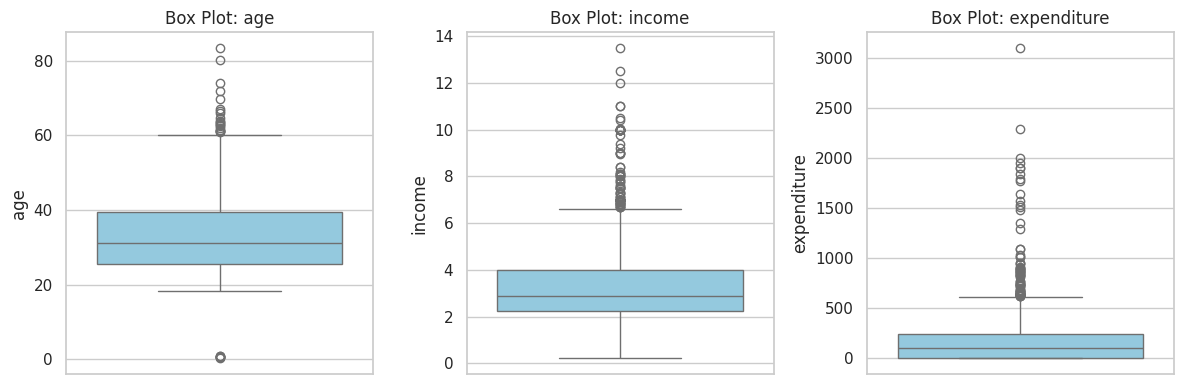

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, column in zip(axes, ["age", "income", "expenditure"]):
    sns.boxplot(y=credit_a3[column], ax=ax, color="skyblue")
    ax.set_title(f"Box Plot: {column}")
    ax.set_ylabel(column)
finish_plot("assessment03_q14_boxplots.png", fig)

**Q15. Identify outliers using the interquartile range method.**

In [54]:
for column in ["income", "expenditure"]:
    q1, q3 = credit_a3[column].quantile([0.25, 0.75])
    iqr_value = q3 - q1
    lower, upper = q1 - 1.5 * iqr_value, q3 + 1.5 * iqr_value
    outlier_count = int(((credit_a3[column] < lower) | (credit_a3[column] > upper)).sum())
    print(f"{column}: lower={lower:.4f}, upper={upper:.4f}, outliers={outlier_count}")

income: lower=-0.3906, upper=6.6344, outliers=77
expenditure: lower=-362.0954, upper=615.7145, outliers=75


**Q16. Remove extreme outliers from the dataset.**

In [55]:
extreme_clean_a3 = credit_a3.copy()
for column in ["income", "expenditure"]:
    q1, q3 = extreme_clean_a3[column].quantile([0.25, 0.75])
    iqr_value = q3 - q1
    lower, upper = q1 - 3 * iqr_value, q3 + 3 * iqr_value
    extreme_clean_a3 = extreme_clean_a3[extreme_clean_a3[column].between(lower, upper)]
print("Rows before:", len(credit_a3), "Rows after removing extreme income/expenditure outliers:", len(extreme_clean_a3))

Rows before: 1319 Rows after removing extreme income/expenditure outliers: 1279


**Q17. Create a histogram for a numerical variable and interpret its distribution.**

Plot saved: /content/eda_project_outputs/assessment03_q17_histogram.png


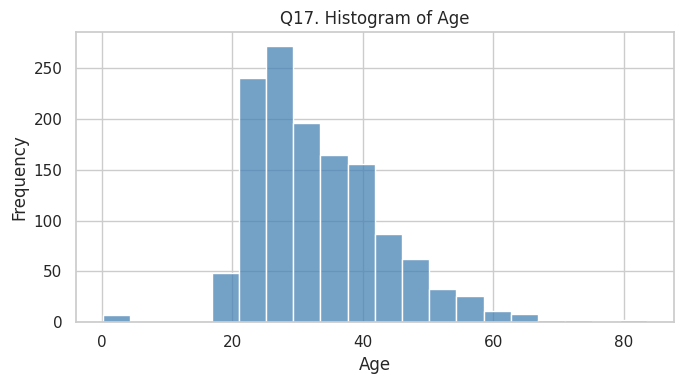

Age distribution is right-skewed (sample skewness=0.841).


In [56]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(credit_a3["age"].dropna(), bins=20, kde=False, ax=ax, color="steelblue")
ax.set(title="Q17. Histogram of Age", xlabel="Age", ylabel="Frequency")
finish_plot("assessment03_q17_histogram.png", fig)
age_skew = float(credit_a3["age"].skew())
shape_text = "right-skewed" if age_skew > 0.5 else "left-skewed" if age_skew < -0.5 else "approximately symmetric"
print(f"Age distribution is {shape_text} (sample skewness={age_skew:.3f}).")

**Q18. Add a density curve to the histogram.**

Plot saved: /content/eda_project_outputs/assessment03_q18_hist_density.png


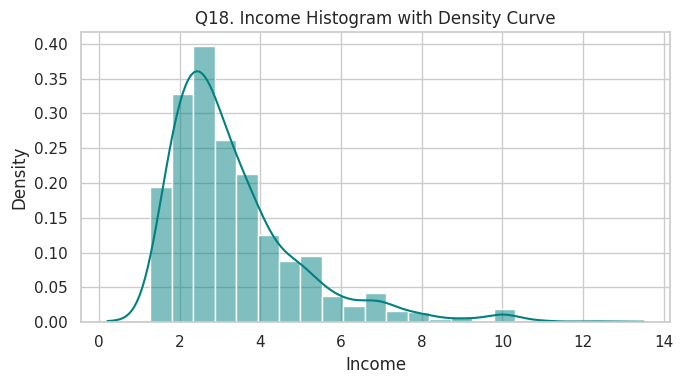

In [57]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(credit_a3["income"].dropna(), bins=25, stat="density", kde=True, ax=ax, color="teal")
ax.set(title="Q18. Income Histogram with Density Curve", xlabel="Income", ylabel="Density")
finish_plot("assessment03_q18_hist_density.png", fig)

**Q19. Create a violin plot**

Plot saved: /content/eda_project_outputs/assessment03_q19_violin.png


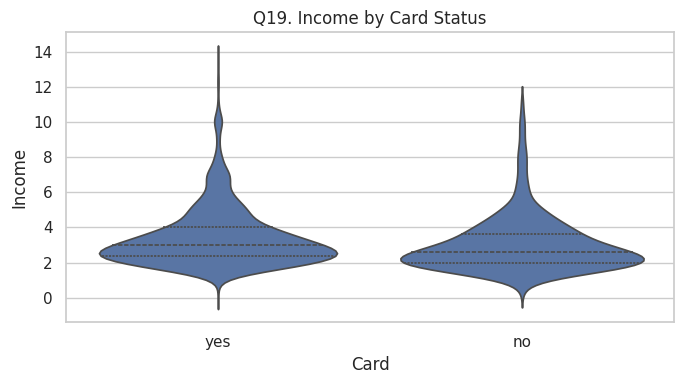

In [58]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.violinplot(data=credit_a3, x="card", y="income", ax=ax, inner="quartile")
ax.set(title="Q19. Income by Card Status", xlabel="Card", ylabel="Income")
finish_plot("assessment03_q19_violin.png", fig)

**Q20. Create a dot plot for a small numerical dataset.**

Plot saved: /content/eda_project_outputs/assessment03_q20_dot_plot.png


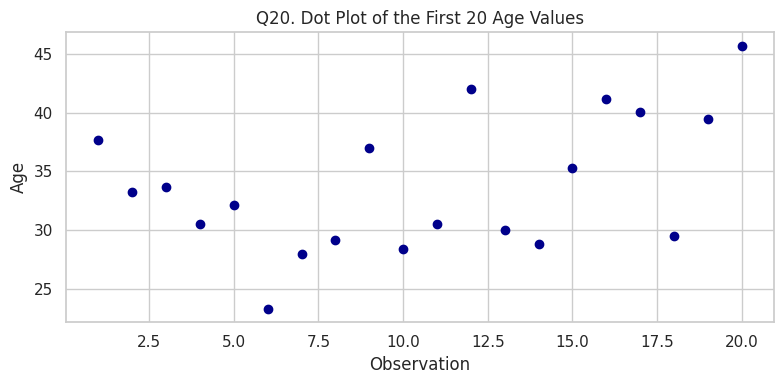

In [59]:
small_values_a3 = credit_a3["age"].head(20).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(np.arange(1, len(small_values_a3) + 1), small_values_a3, color="darkblue")
ax.set(title="Q20. Dot Plot of the First 20 Age Values", xlabel="Observation", ylabel="Age")
finish_plot("assessment03_q20_dot_plot.png", fig)

**Q21. Create a frequency table for a categorical variable.**

In [60]:
card_frequency_a3 = credit_a3["card"].value_counts(dropna=False)
print(card_frequency_a3)

card
yes    1023
no      296
Name: count, dtype: int64


**Q22. Calculate the proportion and percentage of each category.**

In [61]:
card_relative_a3 = credit_a3["card"].value_counts(normalize=True, dropna=False)
print(pd.DataFrame({"Proportion": card_relative_a3, "Percentage": card_relative_a3 * 100}))

      Proportion  Percentage
card                        
yes     0.775588   77.558757
no      0.224412   22.441243


**Q23. Create a bar chart showing the frequency of each category.**

Plot saved: /content/eda_project_outputs/assessment03_q23_bar_chart.png


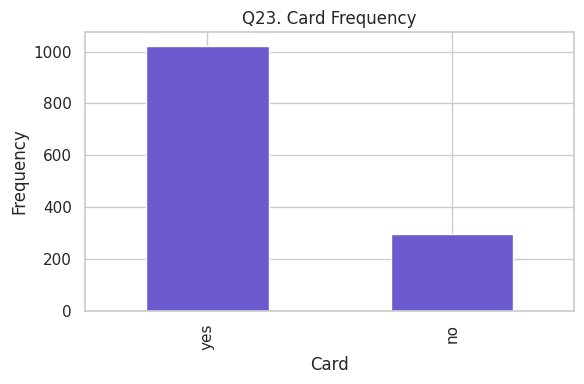

In [62]:
fig, ax = plt.subplots(figsize=(6, 4))
card_frequency_a3.plot(kind="bar", ax=ax, color="slateblue")
ax.set(title="Q23. Card Frequency", xlabel="Card", ylabel="Frequency")
finish_plot("assessment03_q23_bar_chart.png", fig)

**Q24. Create a horizontal bar chart for a variable with several categories.**

Plot saved: /content/eda_project_outputs/assessment03_q24_horizontal_bar.png


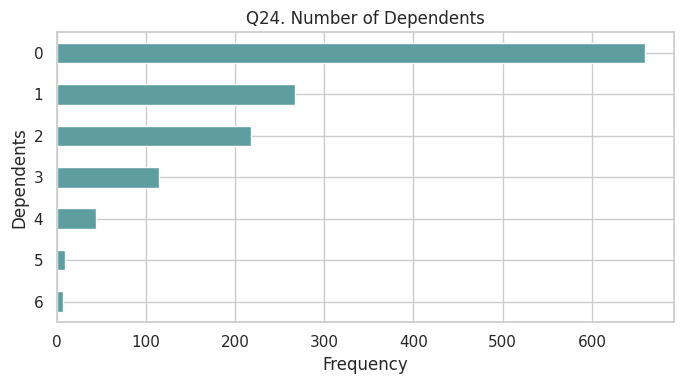

In [63]:
dependent_frequency_a3 = credit_a3["dependents"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
dependent_frequency_a3.sort_values().plot(kind="barh", ax=ax, color="cadetblue")
ax.set(title="Q24. Number of Dependents", xlabel="Frequency", ylabel="Dependents")
finish_plot("assessment03_q24_horizontal_bar.png", fig)

**Q25. Create a percentage bar chart instead of a frequency bar chart.**

Plot saved: /content/eda_project_outputs/assessment03_q25_percentage_bar.png


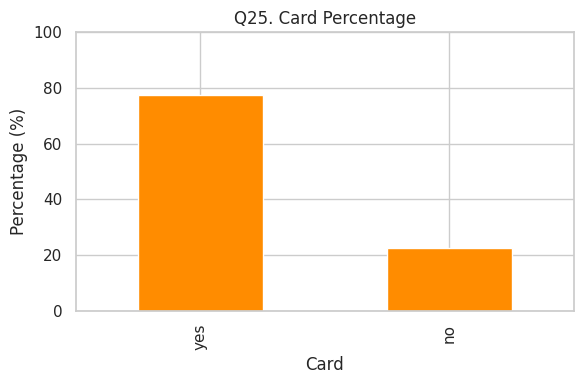

In [64]:
fig, ax = plt.subplots(figsize=(6, 4))
(card_relative_a3 * 100).plot(kind="bar", ax=ax, color="darkorange")
ax.set(title="Q25. Card Percentage", xlabel="Card", ylabel="Percentage (%)", ylim=(0, 100))
finish_plot("assessment03_q25_percentage_bar.png", fig)

**Q26. Create a pie chart for a categorical variable with a small number of categories.**

Plot saved: /content/eda_project_outputs/assessment03_q26_pie.png


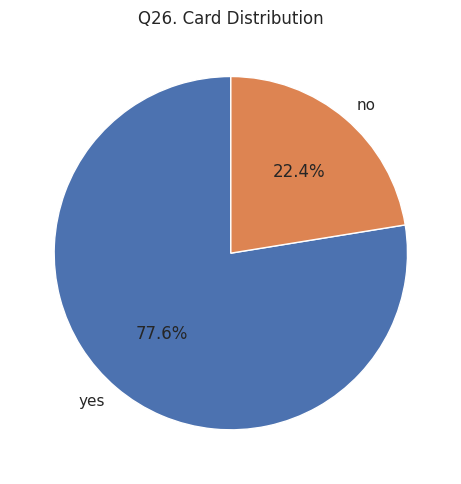

In [65]:
fig, ax = plt.subplots(figsize=(6, 5))
card_frequency_a3.plot(kind="pie", autopct="%1.1f%%", ax=ax, ylabel="", startangle=90)
ax.set_title("Q26. Card Distribution")
finish_plot("assessment03_q26_pie.png", fig)

**Q27. Create a lollipop chart for categorical frequencies.**

Plot saved: /content/eda_project_outputs/assessment03_q27_lollipop.png


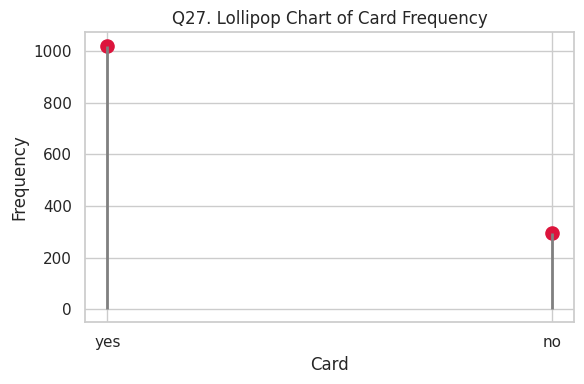

In [66]:
fig, ax = plt.subplots(figsize=(6, 4))
positions_a3 = np.arange(len(card_frequency_a3))
ax.vlines(positions_a3, 0, card_frequency_a3.values, color="gray", linewidth=2)
ax.scatter(positions_a3, card_frequency_a3.values, color="crimson", s=90)
ax.set_xticks(positions_a3, card_frequency_a3.index.astype(str))
ax.set(title="Q27. Lollipop Chart of Card Frequency", xlabel="Card", ylabel="Frequency")
finish_plot("assessment03_q27_lollipop.png", fig)

**Q28. Create a dot chart**

Plot saved: /content/eda_project_outputs/assessment03_q28_dot_chart.png


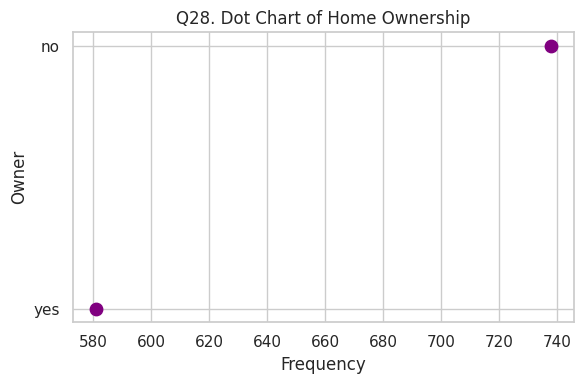

In [67]:
owner_frequency_a3 = credit_a3["owner"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(owner_frequency_a3.values, owner_frequency_a3.index.astype(str), color="purple", s=80)
ax.set(title="Q28. Dot Chart of Home Ownership", xlabel="Frequency", ylabel="Owner")
finish_plot("assessment03_q28_dot_chart.png", fig)

**Q29. Create a density plot using ggplot2.**

Plot saved: /content/eda_project_outputs/assessment03_q29_density.png


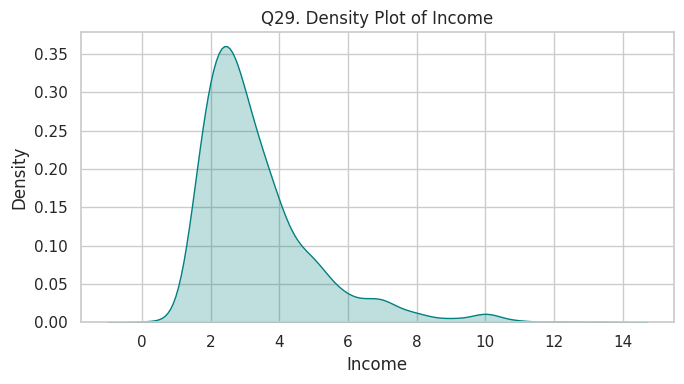

In [68]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(data=credit_a3, x="income", fill=True, ax=ax, color="teal")
ax.set(title="Q29. Density Plot of Income", xlabel="Income", ylabel="Density")
finish_plot("assessment03_q29_density.png", fig)

**Q30. Use facet_wrap() to display the distribution of one variable across different groups while interpreting each distribution separately.**

Plot saved: /content/eda_project_outputs/assessment03_q30_facets.png


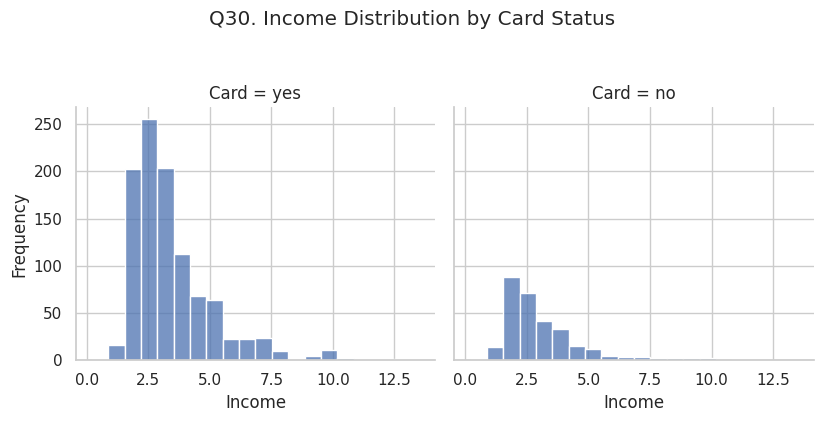

Median income by card status:
 card
no     2.59
yes    3.00
Name: income, dtype: float64


In [69]:
grid_a3 = sns.displot(data=credit_a3, x="income", col="card", bins=20, height=4, aspect=1.05)
grid_a3.set_axis_labels("Income", "Frequency")
grid_a3.set_titles("Card = {col_name}")
grid_a3.fig.suptitle("Q30. Income Distribution by Card Status", y=1.05)
finish_plot("assessment03_q30_facets.png", grid_a3.fig)
print("Median income by card status:\n", credit_a3.groupby("card", observed=False)["income"].median())

# Assessment 4: Bivariate Analysis Using R Programming (Python Equivalent)

**Q1. Load the dataset shared in your mail into the R programming environment and perform the following bivariate analysis and visualization tasks.**

In [70]:
credit_a4 = credit.copy(deep=True)


print(credit_a4.head(6))
print("Numerical columns:", numeric_columns(credit_a4))
print("Categorical columns:", credit_a4.select_dtypes(exclude=np.number).columns.tolist())

   rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
0         1  yes        0  37.66667  4.5200  0.033270   124.983300   yes      no           3      54           1      12
1         2  yes        0  33.25000  2.4200  0.005217     9.854167    no      no           3      34           1      13
2         3  yes        0  33.66667  4.5000  0.004156    15.000000   yes      no           4      58           1       5
3         4  yes        0  30.50000  2.5400  0.065214   137.869200    no      no           0      25           1       7
4         5  yes        0  32.16667  9.7867  0.067051   546.503300   yes      no           2      64           1       5
5         6  yes        0  23.25000  2.5000  0.044438    91.996670    no      no           0      54           1       1
Numerical columns: ['reports', 'age', 'income', 'share', 'expenditure', 'dependents', 'months', 'majorcards', 'active']
Categorical columns: ['card', 'ow

**Q2. Select two suitable categorical variables, create a contingency table, and display their relationship using: a simple stacked bar plot using Base R, and a stacked bar plot using ggplot2.**

card    no  yes
owner          
no     206  532
yes     90  491
Plot saved: /content/eda_project_outputs/assessment04_q2a_stacked_base.png


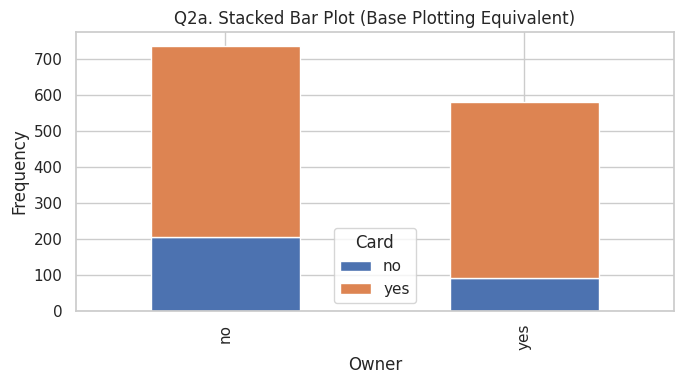

Plot saved: /content/eda_project_outputs/assessment04_q2b_stacked_seaborn.png


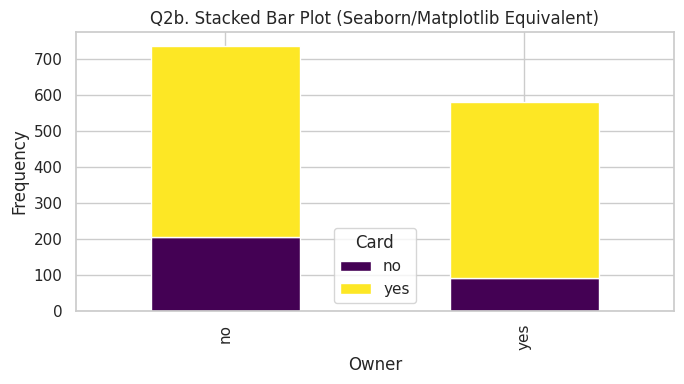

In [71]:
contingency_a4 = pd.crosstab(credit_a4["owner"], credit_a4["card"])
print(contingency_a4)
fig, ax = plt.subplots(figsize=(7, 4))
contingency_a4.plot(kind="bar", stacked=True, ax=ax)
ax.set(title="Q2a. Stacked Bar Plot (Base Plotting Equivalent)", xlabel="Owner", ylabel="Frequency")
ax.legend(title="Card")
finish_plot("assessment04_q2a_stacked_base.png", fig)
fig, ax = plt.subplots(figsize=(7, 4))

contingency_a4.plot(kind="bar", stacked=True, ax=ax, colormap="viridis")
ax.set(title="Q2b. Stacked Bar Plot (Seaborn/Matplotlib Equivalent)", xlabel="Owner", ylabel="Frequency")
ax.legend(title="Card")
finish_plot("assessment04_q2b_stacked_seaborn.png", fig)

**Q3. Select two suitable categorical variables and create a grouped/side-by-side bar plot to compare their frequency distributions.**

Plot saved: /content/eda_project_outputs/assessment04_q3_grouped_bar.png


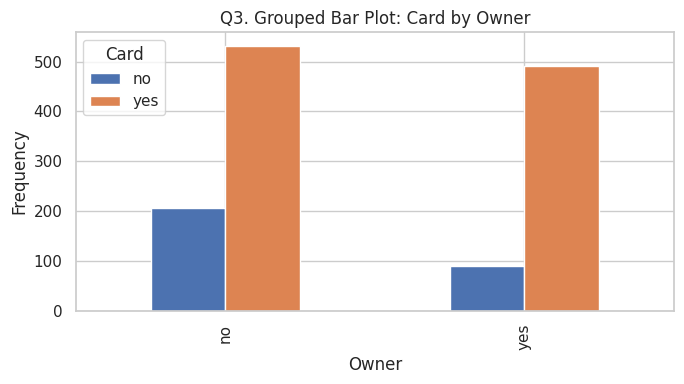

In [72]:
fig, ax = plt.subplots(figsize=(7, 4))
contingency_a4.plot(kind="bar", stacked=False, ax=ax)
ax.set(title="Q3. Grouped Bar Plot: Card by Owner", xlabel="Owner", ylabel="Frequency")
ax.legend(title="Card")
finish_plot("assessment04_q3_grouped_bar.png", fig)

**Q4. Select two suitable numerical variables and generate a scatter plot to analyze the relationship between them.**

Plot saved: /content/eda_project_outputs/assessment04_q4_scatter.png


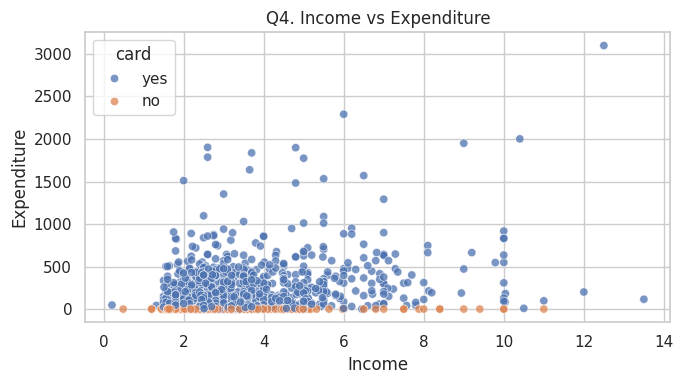

In [73]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=credit_a4, x="income", y="expenditure", hue="card", ax=ax, alpha=0.75)
ax.set(title="Q4. Income vs Expenditure", xlabel="Income", ylabel="Expenditure")
finish_plot("assessment04_q4_scatter.png", fig)

**Q5. Select two appropriate variables and construct a line plot to visualize their relationship or trend.**

Plot saved: /content/eda_project_outputs/assessment04_q5_line_plot.png


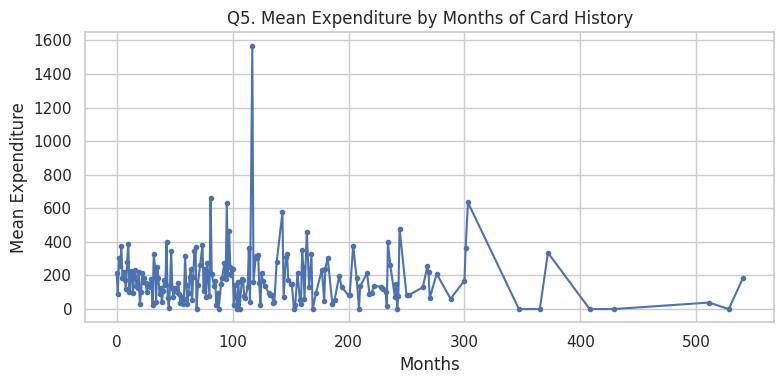

In [74]:
line_data_a4 = credit_a4.groupby("months", as_index=False)["expenditure"].mean().sort_values("months")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(line_data_a4["months"], line_data_a4["expenditure"], marker="o", markersize=3)
ax.set(title="Q5. Mean Expenditure by Months of Card History", xlabel="Months", ylabel="Mean Expenditure")
finish_plot("assessment04_q5_line_plot.png", fig)

**Q6. Select suitable numerical variables and generate a heatmap to represent the relationship among the variables.**

Plot saved: /content/eda_project_outputs/assessment04_q6_heatmap.png


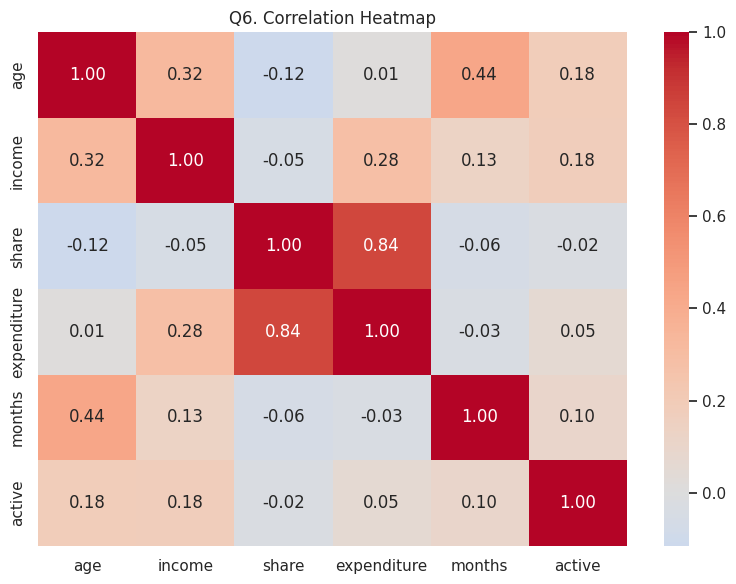

In [75]:
heat_cols_a4 = ["age", "income", "share", "expenditure", "months", "active"]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(credit_a4[heat_cols_a4].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Q6. Correlation Heatmap")
finish_plot("assessment04_q6_heatmap.png", fig)

**Q7. Select suitable variables and construct a bar chart to compare the values or frequencies between two variables.**

Plot saved: /content/eda_project_outputs/assessment04_q7_bar_compare.png


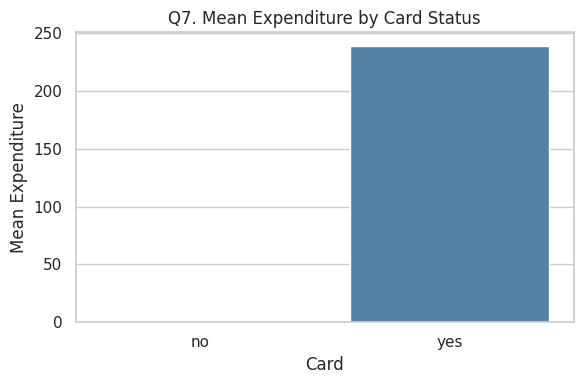

In [76]:
mean_exp_a4 = credit_a4.groupby("card", as_index=False)["expenditure"].mean()
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=mean_exp_a4, x="card", y="expenditure", ax=ax, color="steelblue")
ax.set(title="Q7. Mean Expenditure by Card Status", xlabel="Card", ylabel="Mean Expenditure")
finish_plot("assessment04_q7_bar_compare.png", fig)

**Q8. Select one numerical variable and one categorical variable and generate a density plot to compare the distribution of the numerical variable across different categories.**

Plot saved: /content/eda_project_outputs/assessment04_q8_density.png


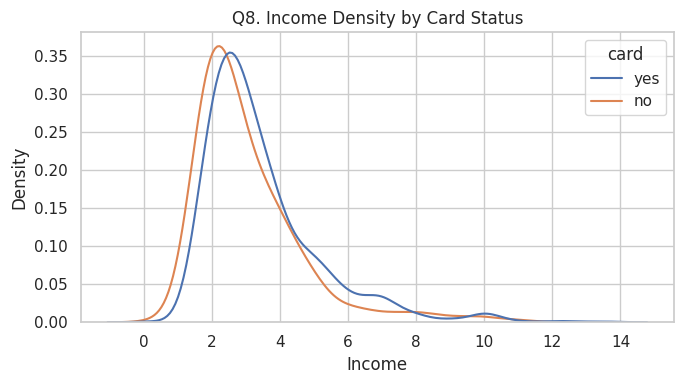

In [77]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(data=credit_a4, x="income", hue="card", common_norm=False, ax=ax)
ax.set(title="Q8. Income Density by Card Status", xlabel="Income", ylabel="Density")
finish_plot("assessment04_q8_density.png", fig)

**Q9. Select one categorical variable and one numerical variable and create a box plot to compare the distribution of the numerical variable across different groups.**

Plot saved: /content/eda_project_outputs/assessment04_q9_boxplot.png


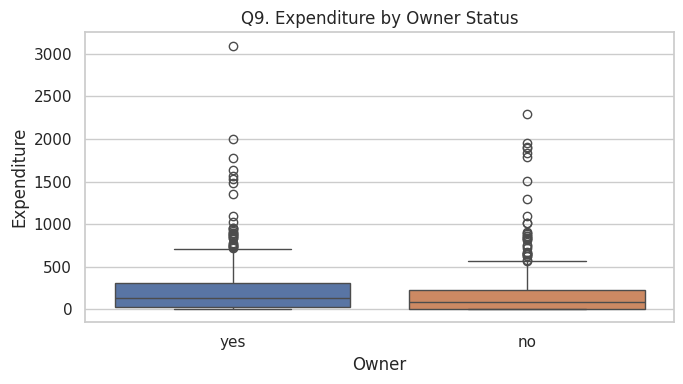

In [78]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=credit_a4, x="owner", y="expenditure", hue="owner", legend=False, ax=ax)
ax.set(title="Q9. Expenditure by Owner Status", xlabel="Owner", ylabel="Expenditure")
finish_plot("assessment04_q9_boxplot.png", fig)

**Q10. Select one categorical variable and one numerical variable and construct a violin plot to visualize the distribution and density of the numerical variable across categories.**

Plot saved: /content/eda_project_outputs/assessment04_q10_violin.png


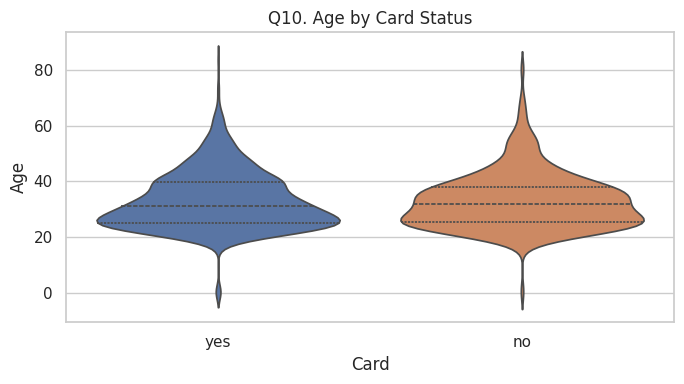

In [79]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.violinplot(data=credit_a4, x="card", y="age", hue="card", legend=False, inner="quartile", ax=ax)
ax.set(title="Q10. Age by Card Status", xlabel="Card", ylabel="Age")
finish_plot("assessment04_q10_violin.png", fig)

**Q11. Select suitable categorical and numerical variables and visualize their distribution by combining a violin plot and box plot in a single graphical representation.**

Plot saved: /content/eda_project_outputs/assessment04_q11_violin_box.png


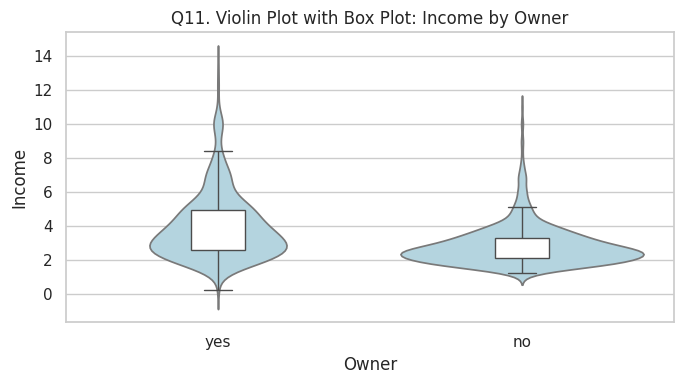

In [80]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.violinplot(data=credit_a4, x="owner", y="income", inner=None, color="lightblue", ax=ax)
sns.boxplot(data=credit_a4, x="owner", y="income", width=0.18, showfliers=False, boxprops={"facecolor": "white", "zorder": 3}, ax=ax)
ax.set(title="Q11. Violin Plot with Box Plot: Income by Owner", xlabel="Owner", ylabel="Income")
finish_plot("assessment04_q11_violin_box.png", fig)

**Q12. Select suitable numerical variables, compute their correlation matrix, and generate a correlogram to study the strength and direction of relationships among the variables.**

                  age    income     share  expenditure    months    active
age          1.000000  0.324653 -0.115697     0.014948  0.436426  0.181070
income       0.324653  1.000000 -0.054429     0.281104  0.130346  0.180540
share       -0.115697 -0.054429  1.000000     0.838779 -0.055348 -0.023474
expenditure  0.014948  0.281104  0.838779     1.000000 -0.029007  0.054724
months       0.436426  0.130346 -0.055348    -0.029007  1.000000  0.100028
active       0.181070  0.180540 -0.023474     0.054724  0.100028  1.000000
Plot saved: /content/eda_project_outputs/assessment04_q12_correlogram.png


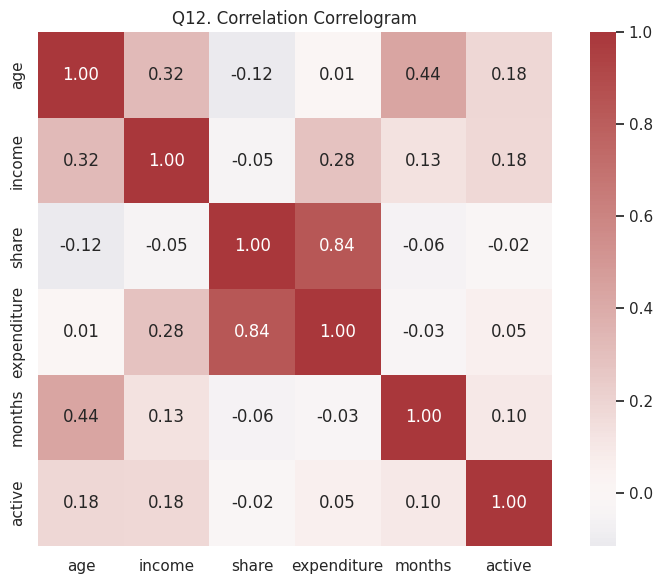

In [81]:
correlation_a4 = credit_a4[heat_cols_a4].corr()
print(correlation_a4)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation_a4, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Q12. Correlation Correlogram")
finish_plot("assessment04_q12_correlogram.png", fig)

**Q13. Provide suitable titles, axis labels, legends, and graphical parameters for all the plots generated.**

In [82]:
print("All Assessment 4 plots above include a title, labeled axes, and legends where a grouping variable is shown.")

All Assessment 4 plots above include a title, labeled axes, and legends where a grouping variable is shown.


# Assessment 5: Multivariate Analysis

**Q1. Load the dataset shared through e-mail into the R environment. Examine the dataset and identify the numerical and categorical variables.**

In [83]:
credit_a5 = credit.copy(deep=True)


print(credit_a5.head())
print("Numerical variables:", numeric_columns(credit_a5))
print("Categorical variables:", credit_a5.select_dtypes(exclude=np.number).columns.tolist())

   rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
0         1  yes        0  37.66667  4.5200  0.033270   124.983300   yes      no           3      54           1      12
1         2  yes        0  33.25000  2.4200  0.005217     9.854167    no      no           3      34           1      13
2         3  yes        0  33.66667  4.5000  0.004156    15.000000   yes      no           4      58           1       5
3         4  yes        0  30.50000  2.5400  0.065214   137.869200    no      no           0      25           1       7
4         5  yes        0  32.16667  9.7867  0.067051   546.503300   yes      no           2      64           1       5
Numerical variables: ['reports', 'age', 'income', 'share', 'expenditure', 'dependents', 'months', 'majorcards', 'active']
Categorical variables: ['card', 'owner', 'selfemp']


**Q2. Create a scatter plot involving three variables, where two numerical variables are represented on the X- and Y-axes, and the third variable is represented using color.**

Plot saved: /content/eda_project_outputs/assessment05_q2_color_scatter.png


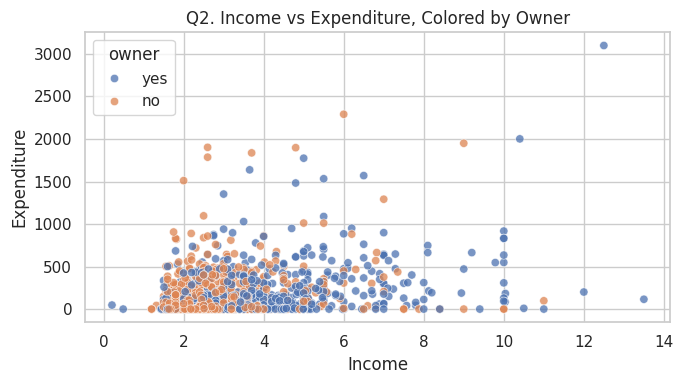

In [84]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=credit_a5, x="income", y="expenditure", hue="owner", ax=ax, alpha=0.75)
ax.set(title="Q2. Income vs Expenditure, Colored by Owner", xlabel="Income", ylabel="Expenditure")
finish_plot("assessment05_q2_color_scatter.png", fig)

**Q3. Create a scatter plot involving four variables, where two numerical variables are represented on the X- and Y-axes, the third variable is represented using color, and the fourth variable is represented using shape.**

Plot saved: /content/eda_project_outputs/assessment05_q3_color_shape_scatter.png


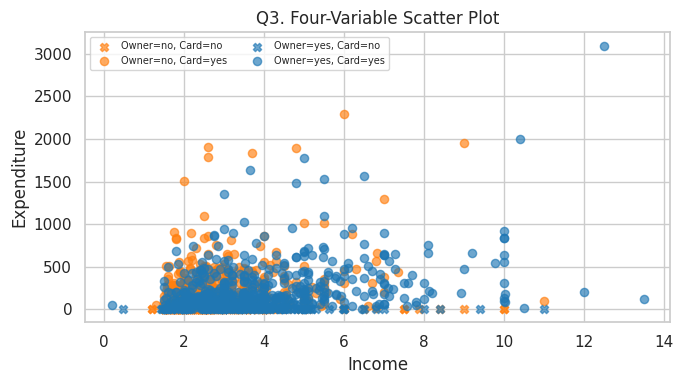

In [85]:
fig, ax = plt.subplots(figsize=(7, 4))
markers_a5 = {"yes": "o", "no": "X"}
for (owner_value, card_value), group in credit_a5.groupby(["owner", "card"], observed=False):
    owner_color = "tab:blue" if str(owner_value) == "yes" else "tab:orange"
    ax.scatter(group["income"], group["expenditure"], label=f"Owner={owner_value}, Card={card_value}",
               color=owner_color, marker=markers_a5.get(str(card_value), "o"), alpha=0.65, s=35)
ax.set(title="Q3. Four-Variable Scatter Plot", xlabel="Income", ylabel="Expenditure")
ax.legend(fontsize=7, ncol=2)
finish_plot("assessment05_q3_color_shape_scatter.png", fig)

**Q4. Create a scatter plot involving four variables, where two numerical variables are represented on the X- and Y-axes, the third variable is represented using color, and the fourth numerical variable is represented using point size.**

Plot saved: /content/eda_project_outputs/assessment05_q4_point_size.png


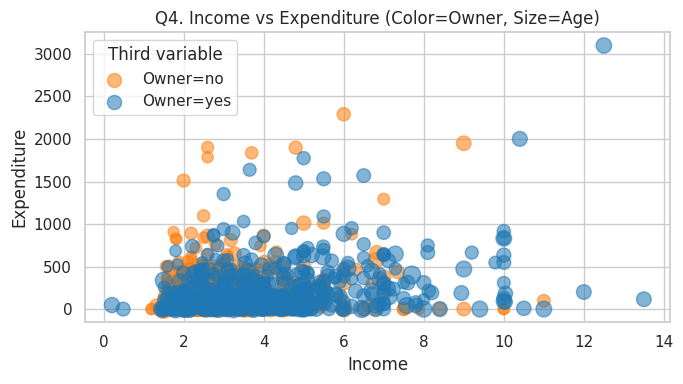

In [86]:
fig, ax = plt.subplots(figsize=(7, 4))
owner_colors_a5 = {"yes": "tab:blue", "no": "tab:orange"}
for owner_value, group in credit_a5.groupby("owner", observed=False):
    ax.scatter(group["income"], group["expenditure"],
               s=20 + 2.0 * group["age"].clip(lower=0), alpha=0.55,
               color=owner_colors_a5.get(str(owner_value), "gray"), label=f"Owner={owner_value}")
ax.set(title="Q4. Income vs Expenditure (Color=Owner, Size=Age)", xlabel="Income", ylabel="Expenditure")
ax.legend(title="Third variable")
finish_plot("assessment05_q4_point_size.png", fig)

**Q5. Construct a bubble plot using three numerical variables, where two variables are represented on the X- and Y-axes, and the third variable determines the size of the bubbles.**

Plot saved: /content/eda_project_outputs/assessment05_q5_bubble_plot.png


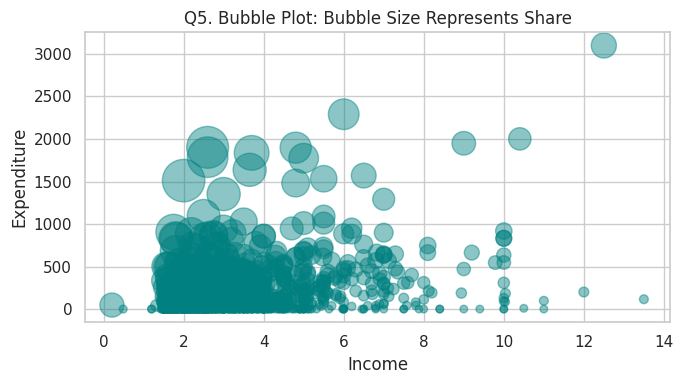

In [87]:
fig, ax = plt.subplots(figsize=(7, 4))
bubble_a5 = ax.scatter(credit_a5["income"], credit_a5["expenditure"],
                       s=30 + 1000 * credit_a5["share"].clip(lower=0), alpha=0.45, color="teal")
ax.set(title="Q5. Bubble Plot: Bubble Size Represents Share", xlabel="Income", ylabel="Expenditure")
finish_plot("assessment05_q5_bubble_plot.png", fig)

**Q6. Generate subplots using facet_wrap() by selecting an appropriate categorical variable from the dataset.**

Plot saved: /content/eda_project_outputs/assessment05_q6_facet_wrap.png


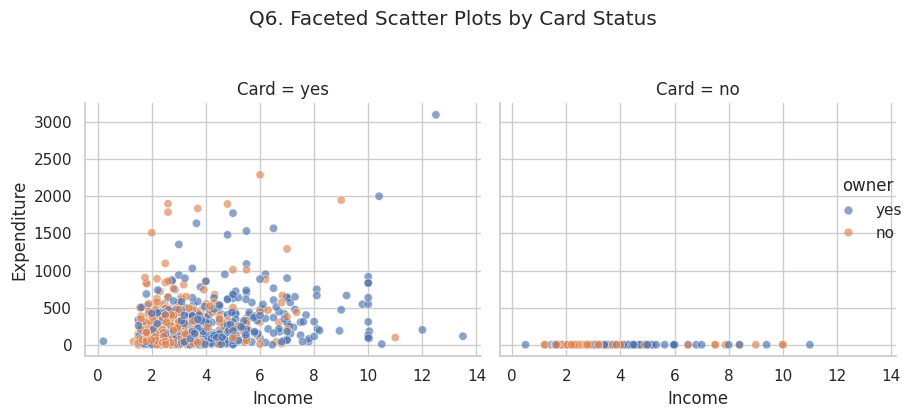

In [88]:
facet_a5 = sns.relplot(data=credit_a5, x="income", y="expenditure", col="card", hue="owner",
                       kind="scatter", alpha=0.65, height=4, aspect=1.05)
facet_a5.set_axis_labels("Income", "Expenditure")
facet_a5.set_titles("Card = {col_name}")
facet_a5.fig.suptitle("Q6. Faceted Scatter Plots by Card Status", y=1.04)
finish_plot("assessment05_q6_facet_wrap.png", facet_a5.fig)

**Q7. Generate subplots using facet_grid() by selecting two appropriate categorical variables from the dataset. Arrange the plots in rows and columns and compare the patterns observed across the different groups.**

Plot saved: /content/eda_project_outputs/assessment05_q7_facet_grid.png


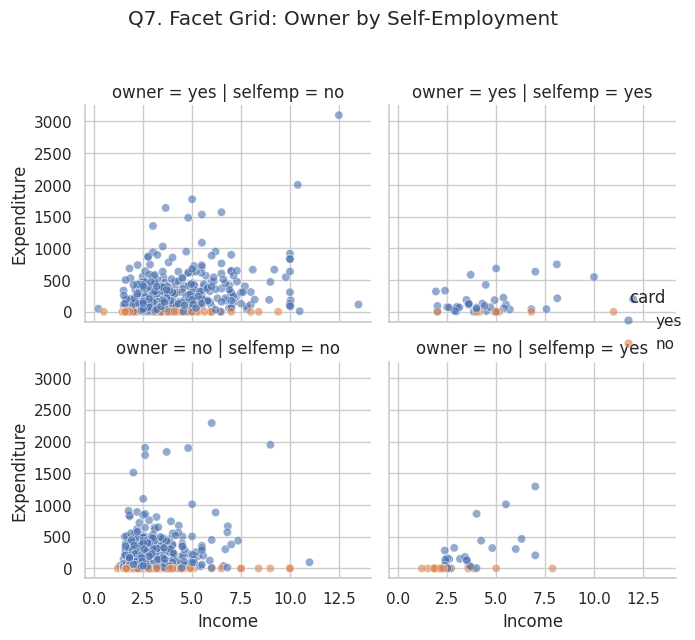

Median expenditure by owner and self-employment:
 owner  selfemp
no     no          85.440000
       yes          4.583333
yes    no         128.249600
       yes         69.273330
Name: expenditure, dtype: float64


In [89]:
facet_grid_a5 = sns.relplot(data=credit_a5, x="income", y="expenditure", row="owner", col="selfemp",
                            hue="card", kind="scatter", alpha=0.6, height=3.1, aspect=1.0)
facet_grid_a5.set_axis_labels("Income", "Expenditure")
facet_grid_a5.fig.suptitle("Q7. Facet Grid: Owner by Self-Employment", y=1.03)
finish_plot("assessment05_q7_facet_grid.png", facet_grid_a5.fig)
print("Median expenditure by owner and self-employment:\n", credit_a5.groupby(["owner", "selfemp"], observed=False)["expenditure"].median())

**Q8. Construct a pairs plot using at least four numerical variables from the dataset. Use the plot to identify possible relationships and correlations among the selected variables.**

Plot saved: /content/eda_project_outputs/assessment05_q8_pairs_plot.png


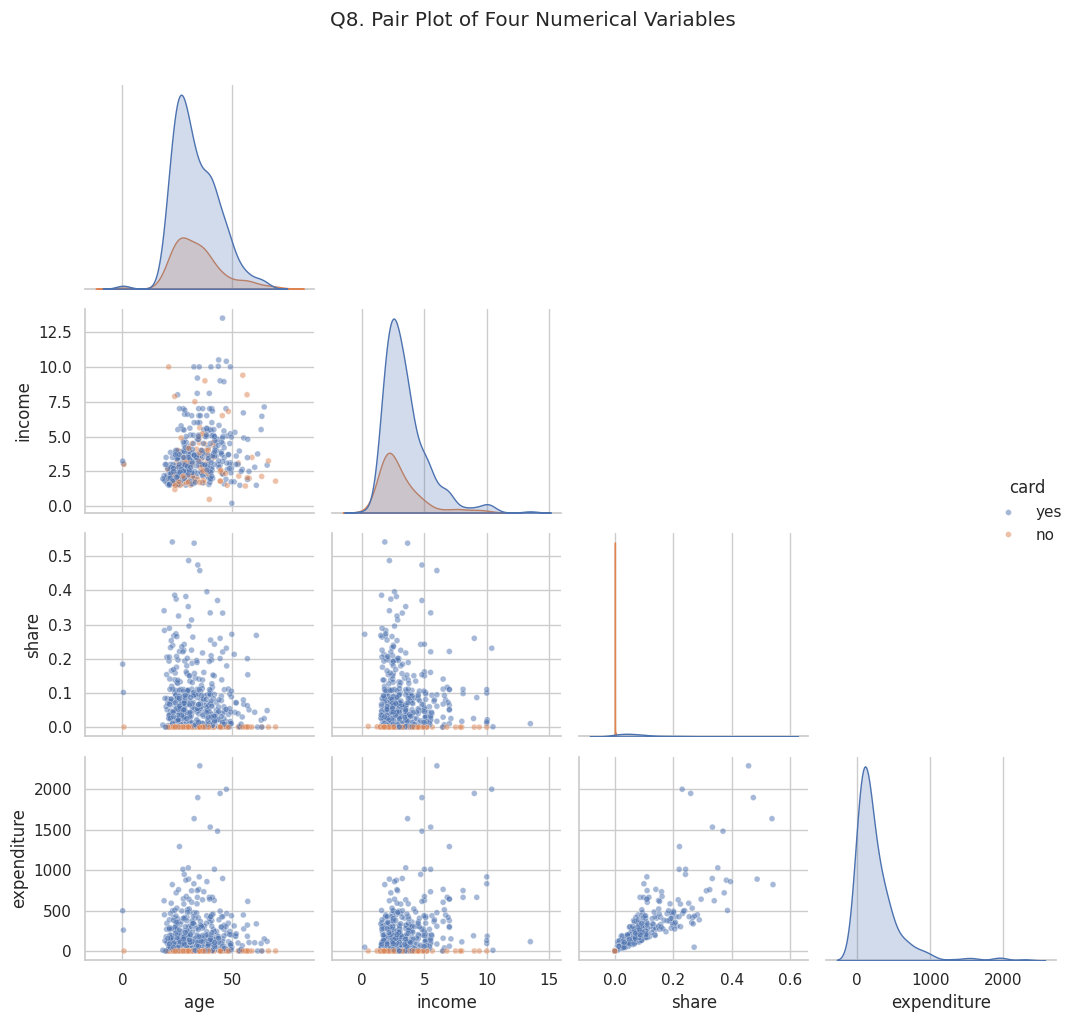

Selected-variable correlations:
                   age    income     share  expenditure
age          1.000000  0.324653 -0.115697     0.014948
income       0.324653  1.000000 -0.054429     0.281104
share       -0.115697 -0.054429  1.000000     0.838779
expenditure  0.014948  0.281104  0.838779     1.000000


In [90]:
pair_vars_a5 = ["age", "income", "share", "expenditure"]
pair_sample_a5 = credit_a5[pair_vars_a5 + ["card"]].sample(min(500, len(credit_a5)), random_state=42)
pair_grid_a5 = sns.pairplot(pair_sample_a5, vars=pair_vars_a5, hue="card", corner=True, plot_kws={"alpha": 0.5, "s": 18})
pair_grid_a5.fig.suptitle("Q8. Pair Plot of Four Numerical Variables", y=1.02)
finish_plot("assessment05_q8_pairs_plot.png", pair_grid_a5.fig)
print("Selected-variable correlations:\n", credit_a5[pair_vars_a5].corr())

**Q9. Create a parallel coordinate plot using at least four numerical variables from the dataset. Differentiate the observations using an appropriate categorical variable.**

Plot saved: /content/eda_project_outputs/assessment05_q9_parallel_coordinates.png


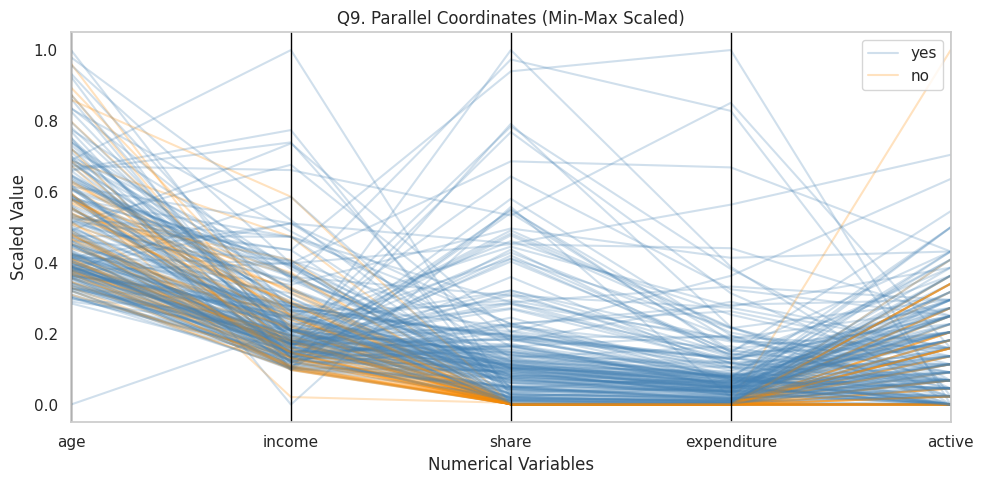

In [91]:
parallel_vars_a5 = ["age", "income", "share", "expenditure", "active"]
parallel_data_a5 = credit_a5[parallel_vars_a5 + ["card"]].dropna().sample(min(250, len(credit_a5)), random_state=42)
parallel_scaled_a5 = pd.DataFrame(MinMaxScaler().fit_transform(parallel_data_a5[parallel_vars_a5]),
                                  columns=parallel_vars_a5)
parallel_scaled_a5["card"] = parallel_data_a5["card"].astype(str).to_numpy()
fig, ax = plt.subplots(figsize=(10, 5))
pd.plotting.parallel_coordinates(parallel_scaled_a5, "card", ax=ax, alpha=0.25, color=["steelblue", "darkorange"])
ax.set(title="Q9. Parallel Coordinates (Min-Max Scaled)", xlabel="Numerical Variables", ylabel="Scaled Value")
finish_plot("assessment05_q9_parallel_coordinates.png", fig)

# Assessment 6: Time Series Analysis

**Q1. Load the built-in AirPassengers dataset in R.**

In [92]:
air_passenger_values = [
    112,118,132,129,121,135,148,148,136,119,104,118,
    115,126,141,135,125,149,170,170,158,133,114,140,
    145,150,178,163,172,178,199,199,184,162,146,166,
    171,180,193,181,183,218,230,242,209,191,172,194,
    196,196,236,235,229,243,264,272,237,211,180,201,
    204,188,235,227,234,264,302,293,259,229,203,229,
    242,233,267,269,270,315,364,347,312,274,237,278,
    284,277,317,313,318,374,413,405,355,306,271,306,
    315,301,356,348,355,422,465,467,404,347,305,336,
    340,318,362,348,363,435,491,505,404,359,310,337,
    360,342,406,396,420,472,548,559,463,407,362,405,
    417,391,419,461,472,535,622,606,508,461,390,432,
]
air_index = pd.date_range(start="1949-01-01", periods=len(air_passenger_values), freq="MS")
air_passengers = pd.Series(air_passenger_values, index=air_index, name="Passengers")


print(air_passengers)

1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
             ... 
1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: Passengers, Length: 144, dtype: int64


**Q2. Explore the first five and last five observations of the dataset.**

In [93]:
print("First five observations:\n", air_passengers.head(5))
print("Last five observations:\n", air_passengers.tail(5))

First five observations:
 1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64
Last five observations:
 1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: Passengers, dtype: int64


**Q3. Identify the starting and ending time periods of the dataset. (start, end)**

In [94]:
print("Start:", air_passengers.index.min(), "End:", air_passengers.index.max())

Start: 1949-01-01 00:00:00 End: 1960-12-01 00:00:00


**Q4. Determine the frequency and time-series characteristics of the dataset. (frequency, class)**

In [95]:
print("Frequency: 12 observations per year (monthly)")
print("Python object type:", type(air_passengers).__name__)
print("Index frequency:", air_passengers.index.freq)
print("Observations:", len(air_passengers))

Frequency: 12 observations per year (monthly)
Python object type: Series
Index frequency: <MonthBegin>
Observations: 144


**Q5. Visualize the monthly passenger trend over the entire period. (plot)**

Plot saved: /content/eda_project_outputs/assessment06_q5_passenger_trend.png


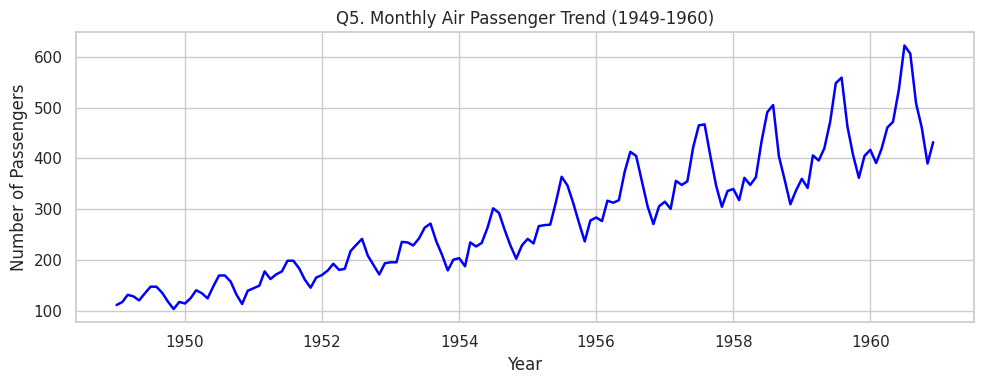

In [96]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(air_passengers.index, air_passengers.values, color="blue", linewidth=1.8)
ax.set(title="Q5. Monthly Air Passenger Trend (1949-1960)", xlabel="Year", ylabel="Number of Passengers")
finish_plot("assessment06_q5_passenger_trend.png", fig)

**Q6. Decompose the time series into trend, seasonal, and random components. (decompose)**

In [97]:
air_decomposition = seasonal_decompose(air_passengers, model="multiplicative", period=12)
print("Decomposition components: observed, trend, seasonal, residual")
print(air_decomposition.seasonal.head(12))

Decomposition components: observed, trend, seasonal, residual
1949-01-01    0.910230
1949-02-01    0.883625
1949-03-01    1.007366
1949-04-01    0.975906
1949-05-01    0.981378
1949-06-01    1.112776
1949-07-01    1.226556
1949-08-01    1.219911
1949-09-01    1.060492
1949-10-01    0.921757
1949-11-01    0.801178
1949-12-01    0.898824
Freq: MS, Name: seasonal, dtype: float64


**Q7. Plot the decomposed components to examine the underlying patterns.**

Plot saved: /content/eda_project_outputs/assessment06_q7_decomposition.png


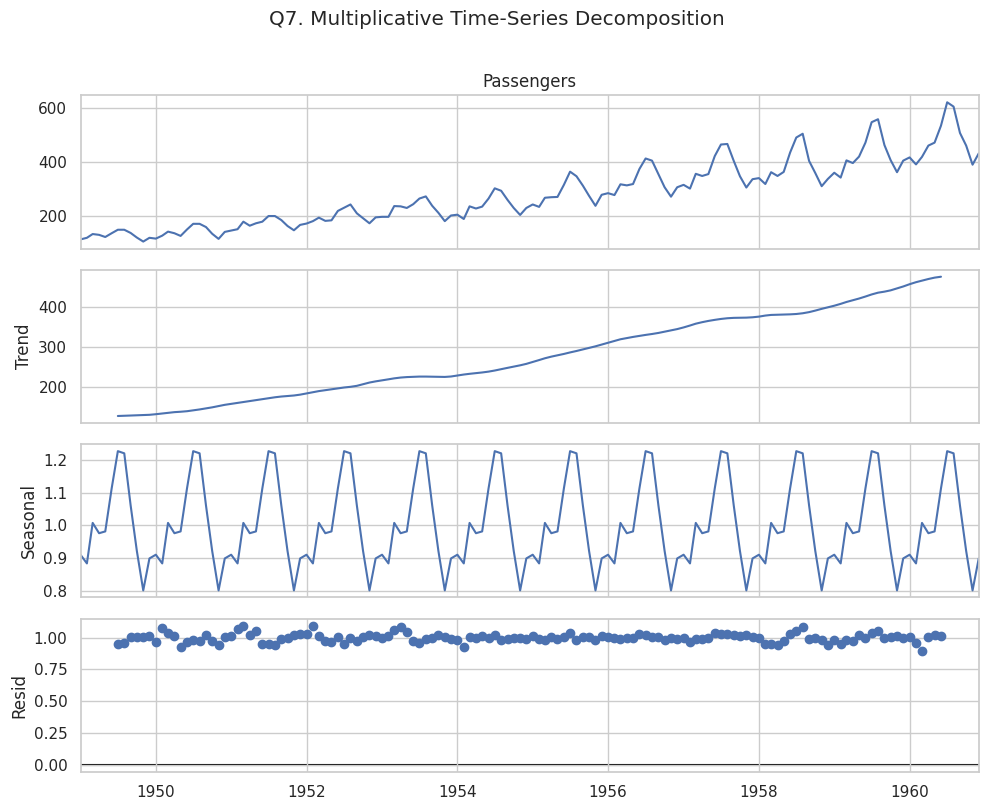

In [98]:
fig = air_decomposition.plot()
fig.set_size_inches(10, 8)
fig.suptitle("Q7. Multiplicative Time-Series Decomposition", y=1.01)
finish_plot("assessment06_q7_decomposition.png", fig)

**Q8. Analyze the autocorrelation and partial autocorrelation of the time series. (acf, pacf)**

Plot saved: /content/eda_project_outputs/assessment06_q8_acf_pacf.png


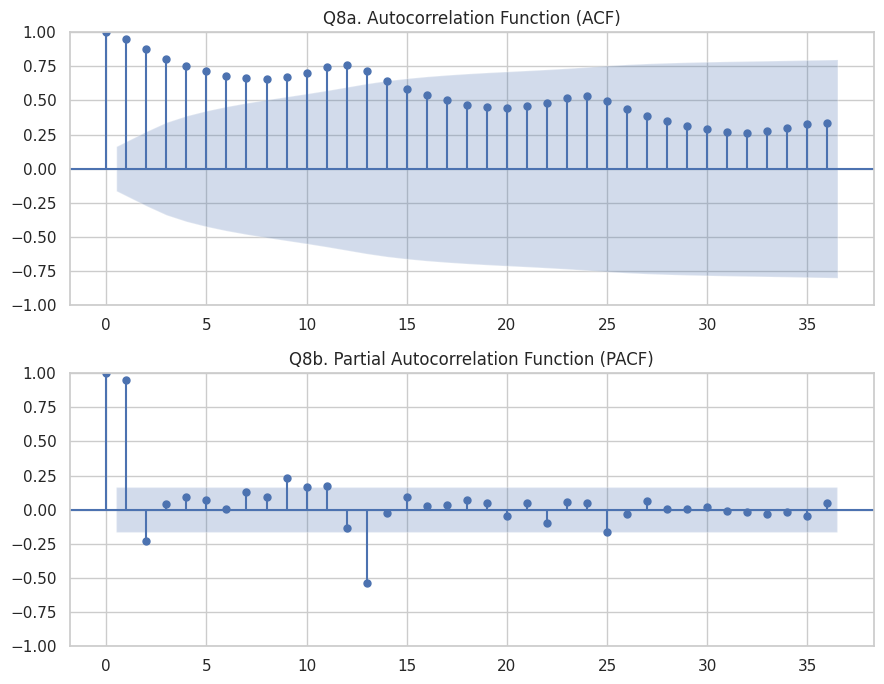

In [99]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7))
plot_acf(air_passengers, lags=36, ax=axes[0])
axes[0].set_title("Q8a. Autocorrelation Function (ACF)")
plot_pacf(air_passengers, lags=36, method="ywm", ax=axes[1])
axes[1].set_title("Q8b. Partial Autocorrelation Function (PACF)")
finish_plot("assessment06_q8_acf_pacf.png", fig)

**Q9. Fit an ARIMA model to the AirPassengers time series. (arima)**

In [100]:
arima_fit = ARIMA(air_passengers, order=(2, 1, 1), seasonal_order=(0, 1, 1, 12)).fit()
print(arima_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


                                    SARIMAX Results                                     
Dep. Variable:                       Passengers   No. Observations:                  144
Model:             ARIMA(2, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -504.180
Date:                          Mon, 19 Oct 2026   AIC                           1018.359
Time:                                  14:59:05   BIC                           1032.735
Sample:                              01-01-1949   HQIC                          1024.201
                                   - 12-01-1960                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6032      0.088      6.879      0.000       0.431       0.775
ar.L2          0.1998      0.098      2.044      0.

**Q10. Display and interpret the fitted ARIMA model parameters and model summary. (summary)**

In [101]:
print(arima_fit.params)
print("Model AIC:", arima_fit.aic)
print("Model BIC:", arima_fit.bic)
print("A lower AIC/BIC is preferred when comparing models fitted to the same series.")

ar.L1         0.603162
ar.L2         0.199789
ma.L1        -0.977298
ma.S.L12     -0.106499
sigma2      127.716189
dtype: float64
Model AIC: 1018.3594769967007
Model BIC: 1032.7354636127063
A lower AIC/BIC is preferred when comparing models fitted to the same series.


**Q11. Forecast the number of passengers for the next 12 months using the fitted ARIMA model. (predict)**

In [102]:
air_forecast = arima_fit.get_forecast(steps=12)
forecast_mean = air_forecast.predicted_mean
forecast_ci = air_forecast.conf_int()
print(pd.DataFrame({"Forecast": forecast_mean, "Lower 95%": forecast_ci.iloc[:, 0], "Upper 95%": forecast_ci.iloc[:, 1]}))

              Forecast   Lower 95%   Upper 95%
1961-01-01  445.934721  423.784029  468.085413
1961-02-01  421.469255  395.337136  447.601373
1961-03-01  453.714763  424.396172  483.033354
1961-04-01  490.660834  459.242916  522.078752
1961-05-01  503.373146  470.411055  536.335238
1961-06-01  565.790383  531.680541  599.900225
1961-07-01  651.686712  616.699073  686.674351
1961-08-01  638.841585  603.169529  674.513641
1961-09-01  541.265323  505.049167  577.481479
1961-10-01  493.602985  456.946408  530.259562
1961-11-01  425.491224  388.471854  462.510594
1961-12-01  467.552220  430.228899  504.875541


**Q12. Visualize the actual and forecasted passenger values with appropriate labels and title. (plot, lines)**

Plot saved: /content/eda_project_outputs/assessment06_q12_forecast.png


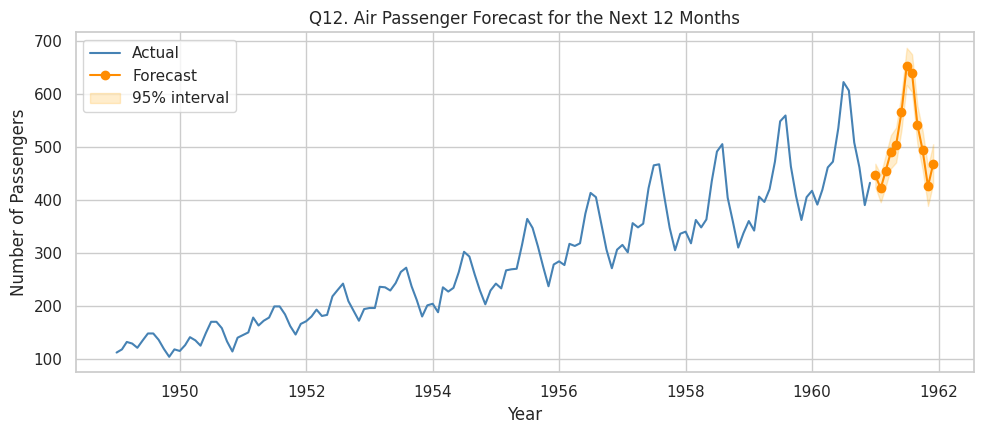

In [103]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(air_passengers.index, air_passengers.values, label="Actual", color="steelblue")
ax.plot(forecast_mean.index, forecast_mean.values, label="Forecast", color="darkorange", marker="o")
ax.fill_between(forecast_ci.index, forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1], color="orange", alpha=0.2, label="95% interval")
ax.set(title="Q12. Air Passenger Forecast for the Next 12 Months", xlabel="Year", ylabel="Number of Passengers")
ax.legend()
finish_plot("assessment06_q12_forecast.png", fig)

# Assessment 7: 1D, 2D and ND Analysis

**Q1. Load the dataset shared via email**

In [104]:
credit_a7 = credit.copy(deep=True)


print(credit_a7.head())

   rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
0         1  yes        0  37.66667  4.5200  0.033270   124.983300   yes      no           3      54           1      12
1         2  yes        0  33.25000  2.4200  0.005217     9.854167    no      no           3      34           1      13
2         3  yes        0  33.66667  4.5000  0.004156    15.000000   yes      no           4      58           1       5
3         4  yes        0  30.50000  2.5400  0.065214   137.869200    no      no           0      25           1       7
4         5  yes        0  32.16667  9.7867  0.067051   546.503300   yes      no           2      64           1       5


**Q2. Compute summary statistics: Mean, Median, Minimum, Maximum, Range, Variance, Standard Deviation, Interquartile Range (IQR), Skewness (using e1071::skewness), and Kurtosis (using e1071::kurtosis).**

In [105]:
variable_a7 = credit_a7["income"].dropna()
summary_a7 = {
    "Mean": variable_a7.mean(),
    "Median": variable_a7.median(),
    "Minimum": variable_a7.min(),
    "Maximum": variable_a7.max(),
    "Range": variable_a7.max() - variable_a7.min(),
    "Variance": variable_a7.var(ddof=1),
    "Standard Deviation": variable_a7.std(ddof=1),
    "IQR": variable_a7.quantile(0.75) - variable_a7.quantile(0.25),
    "Skewness": skew(variable_a7, bias=False),
    "Kurtosis": kurtosis(variable_a7, fisher=False, bias=False),
}
print(pd.Series(summary_a7, name="Income"))

Mean                   3.365376
Median                 2.900000
Minimum                0.210000
Maximum               13.500000
Range                 13.290000
Variance               2.869303
Standard Deviation     1.693902
IQR                    1.756250
Skewness               1.928085
Kurtosis               7.933327
Name: Income, dtype: float64


**Q3. Store these values in a single structured data.frame or named vector and print it.**

In [106]:
summary_table_a7 = pd.DataFrame([summary_a7], index=["income"])
print(summary_table_a7)

            Mean  Median  Minimum  Maximum  Range  Variance  Standard Deviation      IQR  Skewness  Kurtosis
income  3.365376     2.9     0.21     13.5  13.29  2.869303            1.693902  1.75625  1.928085  7.933327


**Q4. Create a frequency distribution table and a relative frequency distribution table for a categorical variable. Generate a Pie Chart and a Bar Plot to represent the distribution.**

Frequency:
 card
yes    1023
no      296
Name: count, dtype: int64
Relative frequency:
 card
yes    0.775588
no     0.224412
Name: proportion, dtype: float64
Plot saved: /content/eda_project_outputs/assessment07_q4_frequency_pie_bar.png


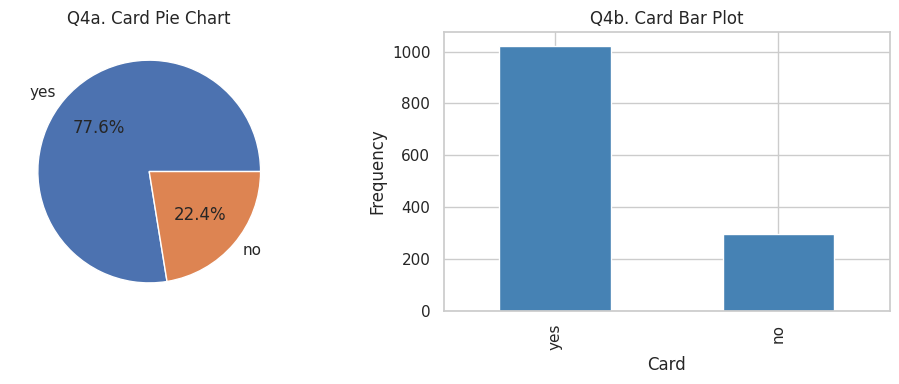

In [107]:
frequency_a7 = credit_a7["card"].value_counts()
relative_frequency_a7 = credit_a7["card"].value_counts(normalize=True)
print("Frequency:\n", frequency_a7)
print("Relative frequency:\n", relative_frequency_a7)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
frequency_a7.plot(kind="pie", autopct="%1.1f%%", ax=axes[0], ylabel="")
axes[0].set_title("Q4a. Card Pie Chart")
frequency_a7.plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set(title="Q4b. Card Bar Plot", xlabel="Card", ylabel="Frequency")
finish_plot("assessment07_q4_frequency_pie_bar.png", fig)

**Q5. Create a frequency distribution table with bin intervals for a numerical variable. Plot its Histogram and a Box Plot to check for outliers.**

income
(0.196, 1.539]       32
(1.539, 2.868]      616
(2.868, 4.197]      391
(4.197, 5.526]      159
(5.526, 6.855]       53
(6.855, 8.184]       39
(8.184, 9.513]        9
(9.513, 10.842]      15
(10.842, 12.171]      3
(12.171, 13.5]        2
Name: count, dtype: int64
Plot saved: /content/eda_project_outputs/assessment07_q5_histogram_boxplot.png


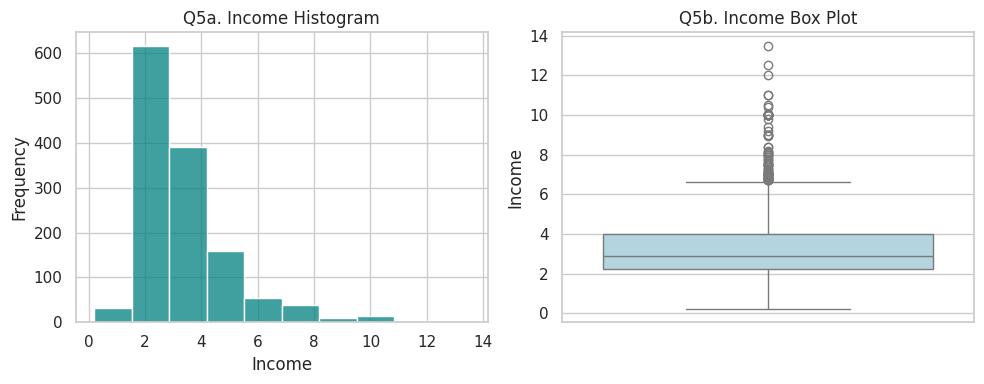

In [108]:
income_bins_a7 = pd.cut(credit_a7["income"], bins=10, include_lowest=True)
print(income_bins_a7.value_counts().sort_index())
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(credit_a7["income"], bins=10, ax=axes[0], color="teal")
axes[0].set(title="Q5a. Income Histogram", xlabel="Income", ylabel="Frequency")
sns.boxplot(y=credit_a7["income"], ax=axes[1], color="lightblue")
axes[1].set(title="Q5b. Income Box Plot", ylabel="Income")
finish_plot("assessment07_q5_histogram_boxplot.png", fig)

**Q6. Choose two categorical variables: Construct a Contingency Table (Cross-tabulation) and compute the row/column percentages using prop.table()**

In [109]:
ct_a7 = pd.crosstab(credit_a7["owner"], credit_a7["card"])
print("Contingency table:\n", ct_a7)
print("Row percentages:\n", ct_a7.div(ct_a7.sum(axis=1), axis=0) * 100)
print("Column percentages:\n", ct_a7.div(ct_a7.sum(axis=0), axis=1) * 100)

Contingency table:
 card    no  yes
owner          
no     206  532
yes     90  491
Row percentages:
 card          no        yes
owner                      
no     27.913279  72.086721
yes    15.490534  84.509466
Column percentages:
 card          no       yes
owner                     
no     69.594595  52.00391
yes    30.405405  47.99609


**Q7. Create a Stacked Bar Plot or Grouped Bar Plot to visualize the relationship.**

Plot saved: /content/eda_project_outputs/assessment07_q7_stacked_bar.png


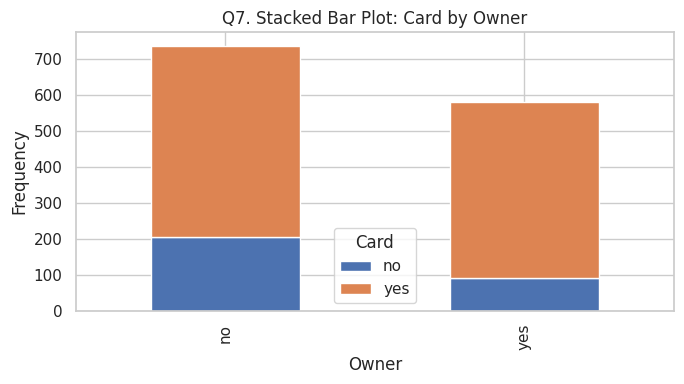

In [110]:
fig, ax = plt.subplots(figsize=(7, 4))
ct_a7.plot(kind="bar", stacked=True, ax=ax)
ax.set(title="Q7. Stacked Bar Plot: Card by Owner", xlabel="Owner", ylabel="Frequency")
ax.legend(title="Card")
finish_plot("assessment07_q7_stacked_bar.png", fig)

**Q8. Select one categorical variable and one numerical variable: Compute the mean, median, and standard deviation of the numerical variable grouped by each category using aggregate()**

In [111]:
group_summary_a7 = credit_a7.groupby("owner", observed=False)["income"].agg(["mean", "median", "std"])
print(group_summary_a7)

           mean   median       std
owner                             
no     2.877435  2.56425  1.237119
yes    3.985171  3.50000  1.971737


**Q9. Generate Side-by-Side Box Plots and a Violin Plot to visualize the numerical distribution across categories.**

Plot saved: /content/eda_project_outputs/assessment07_q9_box_violin.png


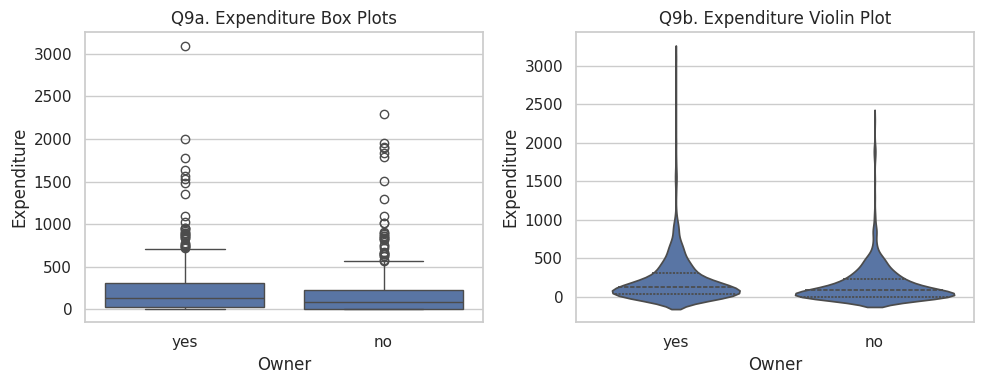

In [112]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=credit_a7, x="owner", y="expenditure", ax=axes[0])
axes[0].set(title="Q9a. Expenditure Box Plots", xlabel="Owner", ylabel="Expenditure")
sns.violinplot(data=credit_a7, x="owner", y="expenditure", ax=axes[1], inner="quartile")
axes[1].set(title="Q9b. Expenditure Violin Plot", xlabel="Owner", ylabel="Expenditure")
finish_plot("assessment07_q9_box_violin.png", fig)

**Q10. Select two numerical variables: Calculate the Pearson and Spearman Correlation Coefficients (cor()) and Construct a Scatter Plot with a fitted linear regression trend line.**

Pearson r=0.2811, p-value=2.23e-25
Spearman rho=0.2275, p-value=5.992e-17
Plot saved: /content/eda_project_outputs/assessment07_q10_correlation_regression.png


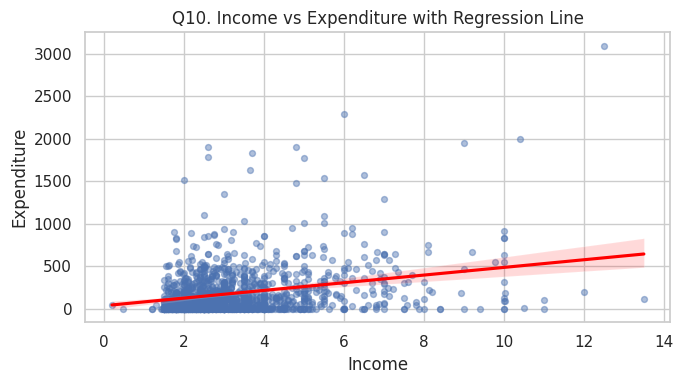

In [113]:
pearson_value = pearsonr(credit_a7["income"], credit_a7["expenditure"])
spearman_value = spearmanr(credit_a7["income"], credit_a7["expenditure"])
print(f"Pearson r={pearson_value.statistic:.4f}, p-value={pearson_value.pvalue:.4g}")
print(f"Spearman rho={spearman_value.statistic:.4f}, p-value={spearman_value.pvalue:.4g}")
fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(data=credit_a7, x="income", y="expenditure", ax=ax, scatter_kws={"alpha": 0.45, "s": 18}, line_kws={"color": "red"})
ax.set(title="Q10. Income vs Expenditure with Regression Line", xlabel="Income", ylabel="Expenditure")
finish_plot("assessment07_q10_correlation_regression.png", fig)

**Q11. Select two categorical features and one numerical feature: Calculate summary statistics (Mean and Standard Deviation) for the numerical variable across all combinations of the two categorical variables and Create a Faceted Box Plot and a Grouped Bar Chart with Error Bars.**

                  mean         std  count
card owner                               
no   no       0.000000    0.000000    206
     yes      0.000000    0.000000     90
yes  no     225.505399  274.175293    532
     yes    252.793084  301.328783    491
Plot saved: /content/eda_project_outputs/assessment07_q11a_faceted_box.png


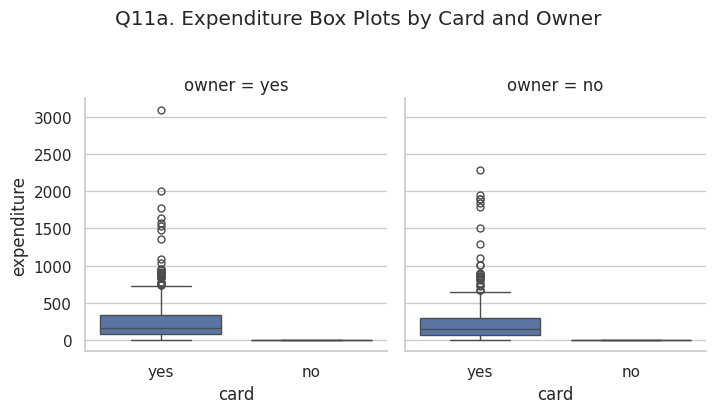

Plot saved: /content/eda_project_outputs/assessment07_q11b_grouped_bar_errorbars.png


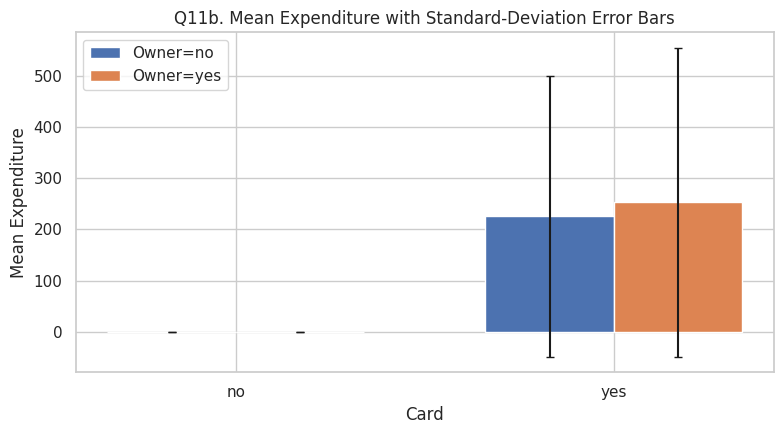

In [114]:
summary_two_cat_a7 = credit_a7.groupby(["card", "owner"], observed=False)["expenditure"].agg(["mean", "std", "count"])
print(summary_two_cat_a7)
facet_box_a7 = sns.catplot(data=credit_a7, x="card", y="expenditure", col="owner", kind="box", height=4, aspect=0.9)
facet_box_a7.fig.suptitle("Q11a. Expenditure Box Plots by Card and Owner", y=1.03)
finish_plot("assessment07_q11a_faceted_box.png", facet_box_a7.fig)
plot_data_a7 = summary_two_cat_a7.reset_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
card_levels_a7 = list(plot_data_a7["card"].drop_duplicates())
owner_levels_a7 = list(plot_data_a7["owner"].drop_duplicates())
width_a7 = 0.34
base_x_a7 = np.arange(len(card_levels_a7))
for j, owner_val in enumerate(owner_levels_a7):
    sub = plot_data_a7[plot_data_a7["owner"] == owner_val].set_index("card").reindex(card_levels_a7)
    ax.bar(base_x_a7 + (j - (len(owner_levels_a7)-1)/2) * width_a7,
           sub["mean"], width=width_a7, yerr=sub["std"].fillna(0), capsize=3, label=f"Owner={owner_val}")
ax.set_xticks(base_x_a7, card_levels_a7)
ax.set(title="Q11b. Mean Expenditure with Standard-Deviation Error Bars", xlabel="Card", ylabel="Mean Expenditure")
ax.legend()
finish_plot("assessment07_q11b_grouped_bar_errorbars.png", fig)

**Q12. Select one categorical variable and two numerical variables: Construct a Scatter Plot of the two numerical features where points are colored/shaped by the categorical feature. compute a correlation matrix between the two numerical variables separately for each category level.**

Plot saved: /content/eda_project_outputs/assessment07_q12_scatter_by_category.png


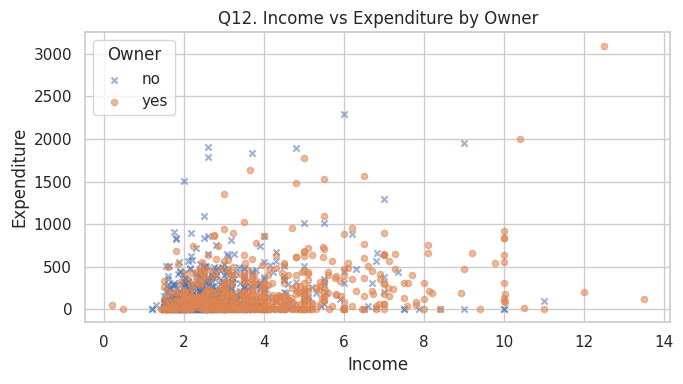

Correlation matrix for owner=no:
                income  expenditure
income       1.000000     0.197212
expenditure  0.197212     1.000000
Correlation matrix for owner=yes:
                income  expenditure
income       1.000000     0.320196
expenditure  0.320196     1.000000


In [115]:
fig, ax = plt.subplots(figsize=(7, 4))
for owner_value, group in credit_a7.groupby("owner", observed=False):
    ax.scatter(group["income"], group["expenditure"], label=str(owner_value), alpha=0.55, s=20, marker="o" if str(owner_value) == "yes" else "x")
ax.set(title="Q12. Income vs Expenditure by Owner", xlabel="Income", ylabel="Expenditure")
ax.legend(title="Owner")
finish_plot("assessment07_q12_scatter_by_category.png", fig)
for owner_value, group in credit_a7.groupby("owner", observed=False):
    print(f"Correlation matrix for owner={owner_value}:\n", group[["income", "expenditure"]].corr())

**Q13. Select at least 3 numerical features from the dataset: Generate a full Correlation Matrix and plot it as a Heatmap**

                  age    income     share  expenditure    months    active
age          1.000000  0.324653 -0.115697     0.014948  0.436426  0.181070
income       0.324653  1.000000 -0.054429     0.281104  0.130346  0.180540
share       -0.115697 -0.054429  1.000000     0.838779 -0.055348 -0.023474
expenditure  0.014948  0.281104  0.838779     1.000000 -0.029007  0.054724
months       0.436426  0.130346 -0.055348    -0.029007  1.000000  0.100028
active       0.181070  0.180540 -0.023474     0.054724  0.100028  1.000000
Plot saved: /content/eda_project_outputs/assessment07_q13_correlation_heatmap.png


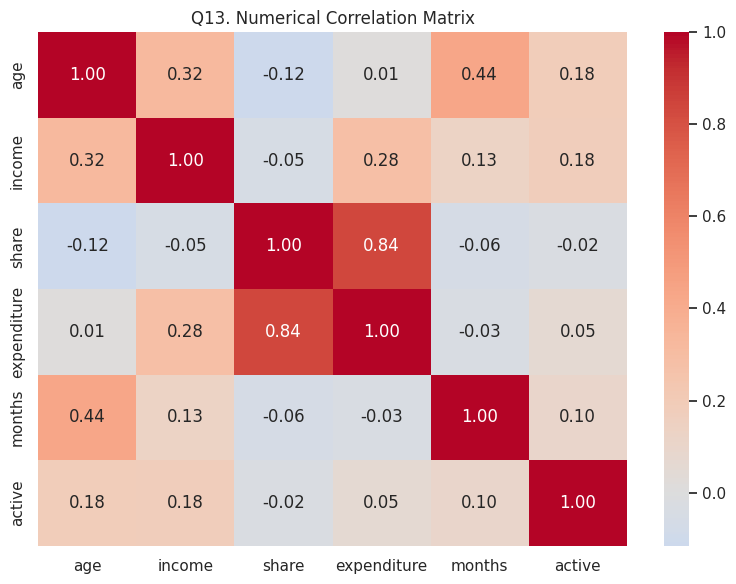

In [116]:
cor_cols_a7 = ["age", "income", "share", "expenditure", "months", "active"]
cor_matrix_a7 = credit_a7[cor_cols_a7].corr()
print(cor_matrix_a7)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cor_matrix_a7, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Q13. Numerical Correlation Matrix")
finish_plot("assessment07_q13_correlation_heatmap.png", fig)

**Q14. Produce a Pairs Plot / Scatterplot Matrix to examine pairwise relationships and distributions simultaneously.**

Plot saved: /content/eda_project_outputs/assessment07_q14_pairs_plot.png


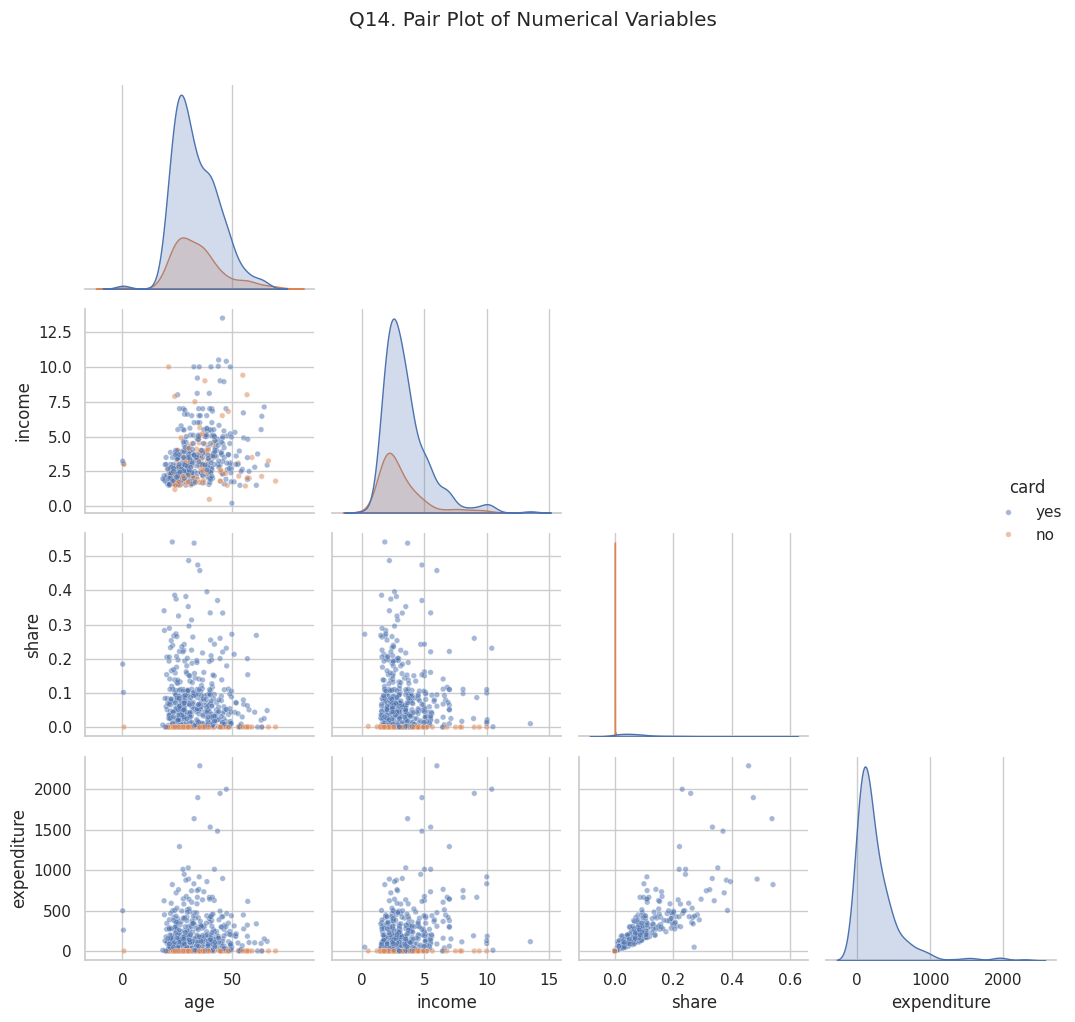

In [117]:
pair_grid_a7 = sns.pairplot(credit_a7[["age", "income", "share", "expenditure", "card"]].sample(min(500, len(credit_a7)), random_state=42),
                            vars=["age", "income", "share", "expenditure"], hue="card", corner=True,
                            plot_kws={"alpha": 0.5, "s": 16})
pair_grid_a7.fig.suptitle("Q14. Pair Plot of Numerical Variables", y=1.02)
finish_plot("assessment07_q14_pairs_plot.png", pair_grid_a7.fig)

# Assessment 8: K-Means and Hierarchical Clustering

**QKMeans-1. Load the dataset shared through e-mail.**

In [118]:
credit_a8 = credit.copy(deep=True)


print("CreditCard.csv loaded in common setup.")

CreditCard.csv loaded in common setup.


**QKMeans-2. View the dataset**

In [119]:
print(credit_a8.head())
print(credit_a8.tail())
print(credit_a8.dtypes)

   rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
0         1  yes        0  37.66667  4.5200  0.033270   124.983300   yes      no           3      54           1      12
1         2  yes        0  33.25000  2.4200  0.005217     9.854167    no      no           3      34           1      13
2         3  yes        0  33.66667  4.5000  0.004156    15.000000   yes      no           4      58           1       5
3         4  yes        0  30.50000  2.5400  0.065214   137.869200    no      no           0      25           1       7
4         5  yes        0  32.16667  9.7867  0.067051   546.503300   yes      no           2      64           1       5
      rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
1314      1315  yes        0  33.58333   4.566  0.002146     7.333333   yes      no           0      94           1      19
1315      1316   no       

**QKMeans-3. Check missing values**

In [120]:
print(credit_a8.isna().sum())

rownames       0
card           0
reports        0
age            0
income         0
share          0
expenditure    0
owner          0
selfemp        0
dependents     0
months         0
majorcards     0
active         0
dtype: int64


**QKMeans-4. Check for the dependent variable distribution. (table)**

In [121]:
print(credit_a8["card"].value_counts(dropna=False))

card
yes    1023
no      296
Name: count, dtype: int64


**QKMeans-5. Select only numerical features for K-Means clustering (Others remove it).**

In [122]:
cluster_numeric_a8 = credit_a8[numeric_columns(credit_a8, exclude_identifier=True)].copy()
cluster_numeric_a8 = cluster_numeric_a8.replace([np.inf, -np.inf], np.nan)
cluster_numeric_a8 = cluster_numeric_a8.fillna(cluster_numeric_a8.median())
print("Selected features:", cluster_numeric_a8.columns.tolist())
print(cluster_numeric_a8.head())

Selected features: ['reports', 'age', 'income', 'share', 'expenditure', 'dependents', 'months', 'majorcards', 'active']
   reports       age  income     share  expenditure  dependents  months  majorcards  active
0        0  37.66667  4.5200  0.033270   124.983300           3      54           1      12
1        0  33.25000  2.4200  0.005217     9.854167           3      34           1      13
2        0  33.66667  4.5000  0.004156    15.000000           4      58           1       5
3        0  30.50000  2.5400  0.065214   137.869200           0      25           1       7
4        0  32.16667  9.7867  0.067051   546.503300           2      64           1       5


**QKMeans-6. Standardize the data. (scale)**

In [123]:
scaler_a8 = StandardScaler()
cluster_scaled_array_a8 = scaler_a8.fit_transform(cluster_numeric_a8)
cluster_scaled_a8 = pd.DataFrame(cluster_scaled_array_a8, columns=cluster_numeric_a8.columns, index=cluster_numeric_a8.index)
print(cluster_scaled_a8.head())

    reports       age    income     share  expenditure  dependents    months  majorcards    active
0 -0.339397  0.439254  0.681894 -0.374787    -0.220766    1.608362 -0.019135    0.472824  0.793701
1 -0.339397  0.003639 -0.558317 -0.671269    -0.643854    1.608362 -0.321037    0.472824  0.952345
2 -0.339397  0.044735  0.670083 -0.682486    -0.624944    2.410112  0.041245    0.472824 -0.316807
3 -0.339397 -0.267592 -0.487448 -0.037185    -0.173411   -0.796887 -0.456893    0.472824  0.000481
4 -0.339397 -0.103209  3.792286 -0.017772     1.328281    0.806613  0.131816    0.472824 -0.316807


**QKMeans-7. Apply K-Means Clustering (kmeans) for center as 2.**

In [124]:
kmeans2_a8 = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels2_a8 = kmeans2_a8.fit_predict(cluster_scaled_a8)

**QKMeans-8. Display K-Means results**

In [125]:
print("Inertia/WCSS:", round(kmeans2_a8.inertia_, 4))
print("Cluster sizes:\n", pd.Series(kmeans_labels2_a8, name="Cluster").value_counts().sort_index())

Inertia/WCSS: 10188.0829
Cluster sizes:
 Cluster
0    835
1    484
Name: count, dtype: int64


**QKMeans-9. Display cluster centers**

In [126]:
centers_a8 = pd.DataFrame(kmeans2_a8.cluster_centers_, columns=cluster_scaled_a8.columns)
print("Cluster centers in standardized units:\n", centers_a8)
print("Cluster centers converted back to original feature units:\n", pd.DataFrame(scaler_a8.inverse_transform(kmeans2_a8.cluster_centers_), columns=cluster_numeric_a8.columns))

Cluster centers in standardized units:
     reports       age    income     share  expenditure  dependents    months  majorcards    active
0 -0.178396 -0.477033 -0.408015  0.123411    -0.020108   -0.365323 -0.289818   -0.053399 -0.274489
1  0.308776  0.825672  0.706213 -0.213606     0.034803    0.632319  0.501631    0.092426  0.475099
Cluster centers converted back to original feature units:
     reports        age    income     share  expenditure  dependents     months  majorcards    active
0  0.216507  28.376495  2.674500  0.080409   179.585467    0.538278  36.068182    0.796651  5.266746
1  0.871636  41.584541  4.561178  0.048521   194.527590    1.782609  88.498965    0.853002  9.991718


**QKMeans-10. Calculate WCSS for K = 1 to 10**

In [127]:
wcss_a8 = []
k_values_a8 = list(range(1, 11))
for k in k_values_a8:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(cluster_scaled_a8)
    wcss_a8.append(model.inertia_)
print(pd.DataFrame({"K": k_values_a8, "WCSS": wcss_a8}))

    K          WCSS
0   1  11871.000000
1   2  10188.082905
2   3   8953.892179
3   4   7957.122685
4   5   7074.750750
5   6   6426.291756
6   7   5981.588417
7   8   5603.334233
8   9   5282.499326
9  10   5052.098196


**QKMeans-11. Display the elbow plot.**

Plot saved: /content/eda_project_outputs/assessment08_q11_elbow_plot.png


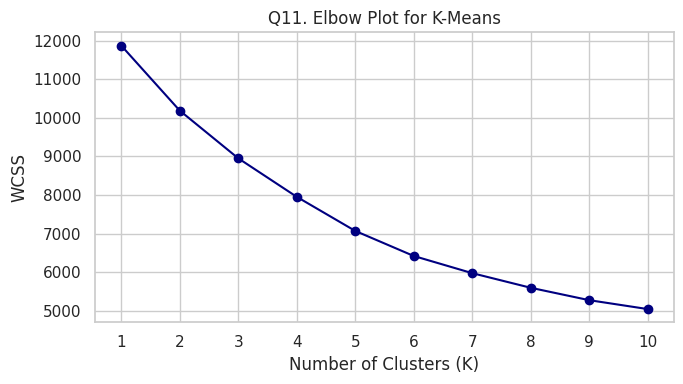

In [128]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_values_a8, wcss_a8, marker="o", color="navy")
ax.set(title="Q11. Elbow Plot for K-Means", xlabel="Number of Clusters (K)", ylabel="WCSS")
ax.set_xticks(k_values_a8)
finish_plot("assessment08_q11_elbow_plot.png", fig)

**QKMeans-12. Apply K-means clustering based on the elbow recommendation.**

In [129]:
x_norm_a8 = (np.array(k_values_a8) - 1) / (10 - 1)
y_norm_a8 = (np.array(wcss_a8) - min(wcss_a8)) / (max(wcss_a8) - min(wcss_a8) + 1e-12)
line_a8 = 1 - x_norm_a8
recommended_k_a8 = int(k_values_a8[int(np.argmax(np.abs(line_a8 - y_norm_a8)))])
print("Elbow-distance recommended K:", recommended_k_a8)
elbow_kmeans_a8 = KMeans(n_clusters=recommended_k_a8, random_state=42, n_init=10)
elbow_labels_a8 = elbow_kmeans_a8.fit_predict(cluster_scaled_a8)
print(pd.Series(elbow_labels_a8, name="Cluster").value_counts().sort_index())

Elbow-distance recommended K: 5
Cluster
0    331
1     66
2    618
3    208
4     96
Name: count, dtype: int64


**QHierarchical-1. Load the dataset shared through e-mail.**

In [130]:
print("CreditCard.csv loaded in common setup.")

CreditCard.csv loaded in common setup.


**QHierarchical-2. View the dataset**

In [131]:
print(credit_a8.head())

   rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
0         1  yes        0  37.66667  4.5200  0.033270   124.983300   yes      no           3      54           1      12
1         2  yes        0  33.25000  2.4200  0.005217     9.854167    no      no           3      34           1      13
2         3  yes        0  33.66667  4.5000  0.004156    15.000000   yes      no           4      58           1       5
3         4  yes        0  30.50000  2.5400  0.065214   137.869200    no      no           0      25           1       7
4         5  yes        0  32.16667  9.7867  0.067051   546.503300   yes      no           2      64           1       5


**QHierarchical-3. Check missing values**

In [132]:
print(credit_a8.isna().sum())

rownames       0
card           0
reports        0
age            0
income         0
share          0
expenditure    0
owner          0
selfemp        0
dependents     0
months         0
majorcards     0
active         0
dtype: int64


**QHierarchical-4. Select only numerical attributes**

In [133]:
print("Numerical attributes used:", cluster_numeric_a8.columns.tolist())

Numerical attributes used: ['reports', 'age', 'income', 'share', 'expenditure', 'dependents', 'months', 'majorcards', 'active']


**QHierarchical-5. Standardize the data (scale)**

In [134]:
print(cluster_scaled_a8.head())

    reports       age    income     share  expenditure  dependents    months  majorcards    active
0 -0.339397  0.439254  0.681894 -0.374787    -0.220766    1.608362 -0.019135    0.472824  0.793701
1 -0.339397  0.003639 -0.558317 -0.671269    -0.643854    1.608362 -0.321037    0.472824  0.952345
2 -0.339397  0.044735  0.670083 -0.682486    -0.624944    2.410112  0.041245    0.472824 -0.316807
3 -0.339397 -0.267592 -0.487448 -0.037185    -0.173411   -0.796887 -0.456893    0.472824  0.000481
4 -0.339397 -0.103209  3.792286 -0.017772     1.328281    0.806613  0.131816    0.472824 -0.316807


**QHierarchical-6. Calculate Euclidean distance (dist)**

In [135]:
euclidean_distances_a8 = pdist(cluster_scaled_a8, metric="euclidean")
print("Number of pairwise distances:", len(euclidean_distances_a8))
print("First 10 distances:", np.round(euclidean_distances_a8[:10], 4))

Number of pairwise distances: 869221
First 10 distances: [1.453  1.5144 2.9307 3.794  3.5077 1.886  3.2367 4.2533 2.8723 2.3362]


**QHierarchical-7. Perform Hierarchical Clustering using Ward's method (hclust)**

In [136]:
ward_linkage_a8 = linkage(cluster_scaled_a8, method="ward", metric="euclidean")
print("Ward linkage matrix shape:", ward_linkage_a8.shape)

Ward linkage matrix shape: (1318, 4)


**QHierarchical-8. Plot the dendrogram. (plot)**

Plot saved: /content/eda_project_outputs/assessment08_q8_dendrogram.png


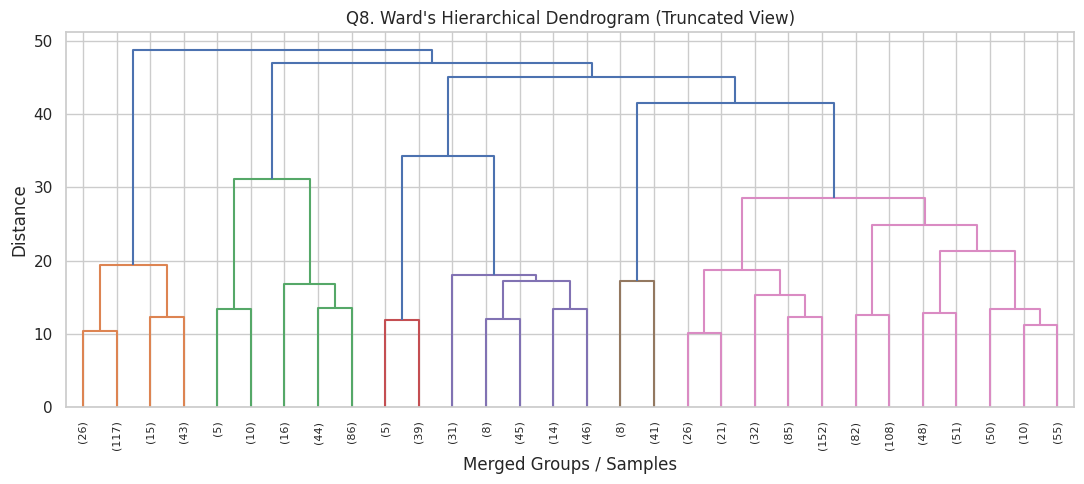

The dendrogram view is truncated to 30 terminal groups for readability; clustering used every observation.


In [137]:
fig, ax = plt.subplots(figsize=(11, 5))
dendrogram(ward_linkage_a8, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8, ax=ax)
ax.set(title="Q8. Ward's Hierarchical Dendrogram (Truncated View)", xlabel="Merged Groups / Samples", ylabel="Distance")
finish_plot("assessment08_q8_dendrogram.png", fig)
print("The dendrogram view is truncated to 30 terminal groups for readability; clustering used every observation.")

**QHierarchical-9. Divide the data into 3 clusters and Display cluster assignments(cutree)**

In [138]:
hierarchical_labels_a8 = fcluster(ward_linkage_a8, t=3, criterion="maxclust")
credit_a8_hierarchical = credit_a8.copy()
credit_a8_hierarchical["hierarchical_cluster"] = hierarchical_labels_a8
print(credit_a8_hierarchical[["hierarchical_cluster"]].head(20))

    hierarchical_cluster
0                      3
1                      3
2                      3
3                      3
4                      3
5                      3
6                      3
7                      3
8                      2
9                      3
10                     3
11                     3
12                     1
13                     3
14                     1
15                     3
16                     3
17                     3
18                     3
19                     3


**QHierarchical-10. Display number of samples in each cluster. (table)**

In [139]:
print(credit_a8_hierarchical["hierarchical_cluster"].value_counts().sort_index())

hierarchical_cluster
1    201
2    161
3    957
Name: count, dtype: int64


# Assessment 9: Principal Component Analysis (CreditCard.csv)

**Q1. Load the dataset sent to your email into R, and verify that the packages ggplot2, ggfortify, FactoMineR, and factoextra are loaded.**

In [140]:
credit_a9 = credit.copy(deep=True)


print("Python equivalents use pandas, scikit-learn, seaborn and matplotlib.")
print("These Python packages replace the R-specific package requirement for the analysis.")
print(credit_a9.head())

Python equivalents use pandas, scikit-learn, seaborn and matplotlib.
These Python packages replace the R-specific package requirement for the analysis.
   rownames card  reports       age  income     share  expenditure owner selfemp  dependents  months  majorcards  active
0         1  yes        0  37.66667  4.5200  0.033270   124.983300   yes      no           3      54           1      12
1         2  yes        0  33.25000  2.4200  0.005217     9.854167    no      no           3      34           1      13
2         3  yes        0  33.66667  4.5000  0.004156    15.000000   yes      no           4      58           1       5
3         4  yes        0  30.50000  2.5400  0.065214   137.869200    no      no           0      25           1       7
4         5  yes        0  32.16667  9.7867  0.067051   546.503300   yes      no           2      64           1       5


**Q2. Display the total number of rows and columns in the dataset.**

In [141]:
print("Rows and columns:", credit_a9.shape)

Rows and columns: (1319, 13)


**Q3. Extract only the numeric columns, clean the data, and normalize it using the scale() function into an object named data_scaled.**

In [142]:
numeric_data_a9 = credit_a9[numeric_columns(credit_a9, exclude_identifier=True)].copy()
numeric_data_a9 = numeric_data_a9.replace([np.inf, -np.inf], np.nan).dropna()
numeric_data_a9 = numeric_data_a9.loc[:, numeric_data_a9.std(ddof=0) > 0]
data_scaler_a9 = StandardScaler()
data_scaled_a9 = pd.DataFrame(data_scaler_a9.fit_transform(numeric_data_a9),
                              columns=numeric_data_a9.columns, index=numeric_data_a9.index)
print(data_scaled_a9.head())
print("Note: the numeric identifier column 'rownames' is excluded from PCA features.")

    reports       age    income     share  expenditure  dependents    months  majorcards    active
0 -0.339397  0.439254  0.681894 -0.374787    -0.220766    1.608362 -0.019135    0.472824  0.793701
1 -0.339397  0.003639 -0.558317 -0.671269    -0.643854    1.608362 -0.321037    0.472824  0.952345
2 -0.339397  0.044735  0.670083 -0.682486    -0.624944    2.410112  0.041245    0.472824 -0.316807
3 -0.339397 -0.267592 -0.487448 -0.037185    -0.173411   -0.796887 -0.456893    0.472824  0.000481
4 -0.339397 -0.103209  3.792286 -0.017772     1.328281    0.806613  0.131816    0.472824 -0.316807
Note: the numeric identifier column 'rownames' is excluded from PCA features.


**Q4. Perform Principal Component Analysis on data_scaled using either the PCA() or prcomp() function, and print its summary.**

In [143]:
pca_result_a9 = PCA()
pca_scores_array_a9 = pca_result_a9.fit_transform(data_scaled_a9)
variance_a9 = 100 * pca_result_a9.explained_variance_ratio_
pca_summary_a9 = pd.DataFrame({
    "Standard Deviation": np.sqrt(pca_result_a9.explained_variance_),
    "Proportion of Variance (%)": variance_a9,
    "Cumulative Variance (%)": np.cumsum(variance_a9),
}, index=[f"PC{i}" for i in range(1, len(variance_a9) + 1)])
print(pca_summary_a9.round(4))

     Standard Deviation  Proportion of Variance (%)  Cumulative Variance (%)
PC1              1.3910                     21.4826                  21.4826
PC2              1.3835                     21.2506                  42.7332
PC3              1.0737                     12.7998                  55.5331
PC4              1.0317                     11.8166                  67.3497
PC5              0.9762                     10.5798                  77.9295
PC6              0.8507                      8.0356                  85.9650
PC7              0.8119                      7.3186                  93.2836
PC8              0.7127                      5.6390                  98.9226
PC9              0.3115                      1.0774                 100.0000


**Q5. Plot a scree plot showing the percentage of variance for each component with data labels, setting the y-axis limit from 0 to 60.**

Plot saved: /content/eda_project_outputs/assessment09_q5_scree_plot.png


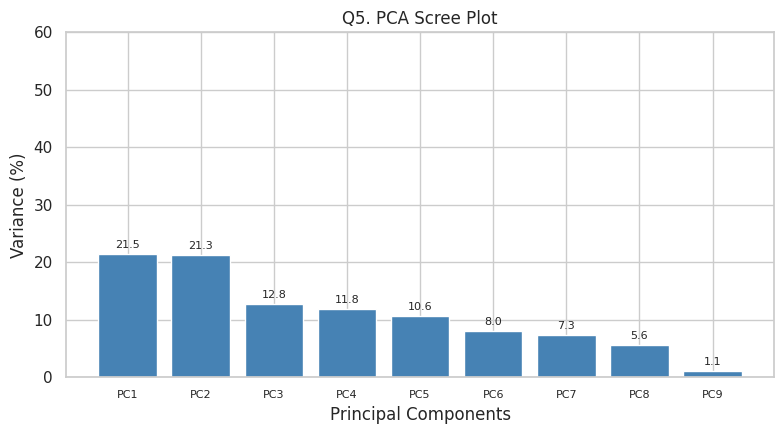

In [144]:
fig, ax = plt.subplots(figsize=(8, 4.5))
pcs_a9 = np.arange(1, len(variance_a9) + 1)
ax.bar(pcs_a9, variance_a9, color="steelblue")
for x_value, y_value in zip(pcs_a9, variance_a9):
    ax.text(x_value, min(y_value + 0.7, 59), f"{y_value:.1f}", ha="center", va="bottom", fontsize=8)
ax.set(title="Q5. PCA Scree Plot", xlabel="Principal Components", ylabel="Variance (%)", ylim=(0, 60))
ax.set_xticks(pcs_a9, [f"PC{i}" for i in pcs_a9], fontsize=8)
finish_plot("assessment09_q5_scree_plot.png", fig)

**Q6. Create a PCA biplot with non-overlapping labels and a proper title.**

Plot saved: /content/eda_project_outputs/assessment09_q6_biplot.png


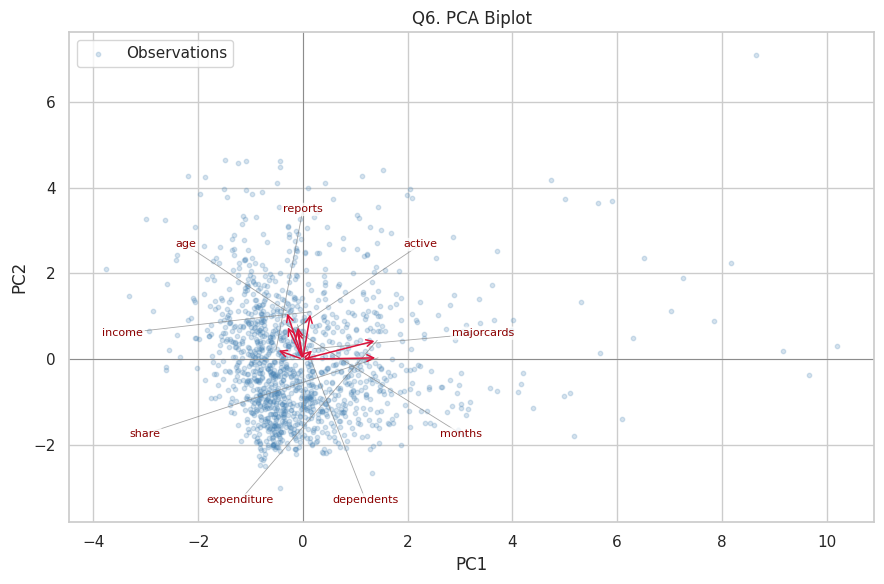

In [145]:
loadings_a9 = pca_result_a9.components_.T[:, :2]
scores_a9 = pca_scores_array_a9[:, :2]
score_limit_a9 = max(np.percentile(np.abs(scores_a9), 90), 1.0)
loading_limit_a9 = max(np.max(np.abs(loadings_a9)), 1e-9)
arrow_scale_a9 = 0.72 * score_limit_a9 / loading_limit_a9
arrow_ends_a9 = loadings_a9 * arrow_scale_a9
spread_a9 = max(np.ptp(scores_a9[:, 0]), np.ptp(scores_a9[:, 1]))

label_radius_a9 = max(0.75 * score_limit_a9, 0.25 * spread_a9)
label_angles_a9 = np.linspace(0, 2 * np.pi, len(data_scaled_a9.columns), endpoint=False) + np.pi / 2
repelled_labels_a9 = np.column_stack((label_radius_a9 * np.cos(label_angles_a9),
                                     label_radius_a9 * np.sin(label_angles_a9)))
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(scores_a9[:, 0], scores_a9[:, 1], s=10, alpha=0.22, color="steelblue", label="Observations")
for i, variable in enumerate(data_scaled_a9.columns):
    x_end, y_end = arrow_ends_a9[i]
    x_label, y_label = repelled_labels_a9[i]
    ax.annotate("", xy=(x_end, y_end), xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": "crimson", "lw": 1.1})
    ax.plot([x_end, x_label], [y_end, y_label], color="gray", linewidth=0.6, alpha=0.7)
    ax.text(x_label, y_label, variable, color="darkred", fontsize=8, ha="center", va="center",
            bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.75})
ax.axhline(0, color="gray", linewidth=0.6)
ax.axvline(0, color="gray", linewidth=0.6)
ax.set(title="Q6. PCA Biplot", xlabel="PC1", ylabel="PC2")
ax.legend(loc="best")
finish_plot("assessment09_q6_biplot.png", fig)

**Q7. Extract the PCA scores into a data frame named pca_scores and display the first six rows.**

In [146]:
pca_scores_a9 = pd.DataFrame(pca_scores_array_a9, columns=[f"PC{i}" for i in range(1, pca_scores_array_a9.shape[1] + 1)], index=data_scaled_a9.index)
print(pca_scores_a9.head(6))

        PC1       PC2       PC3       PC4       PC5       PC6       PC7       PC8       PC9
0 -0.405586  1.413799  0.464499  1.164030 -0.019493  0.489426 -0.645477 -0.053002 -0.098061
1 -0.869500  0.398000  0.739273  0.986700 -0.017833  0.828224 -1.403132  0.099032  0.114429
2 -0.807580  1.057110  0.047173  2.075870 -0.181422 -0.328928 -1.074289 -0.392052 -0.163640
3  0.099055 -0.875453  0.300102 -0.147818  0.690598  0.261569  0.185755  0.232558  0.033531
4  1.229222  2.431010  0.159809  1.903748 -0.104344 -0.722865  2.026060 -1.246928 -0.009348
5 -0.065996 -1.461084 -0.143790  0.096580  0.795781 -0.440127  0.153635 -0.509361  0.099033


**Q8. Draw a scatter plot of the first two principal components (PC1 vs. PC2) with blue circular points and your registration number in the title**

Plot saved: /content/eda_project_outputs/assessment09_q8_pc1_pc2.png


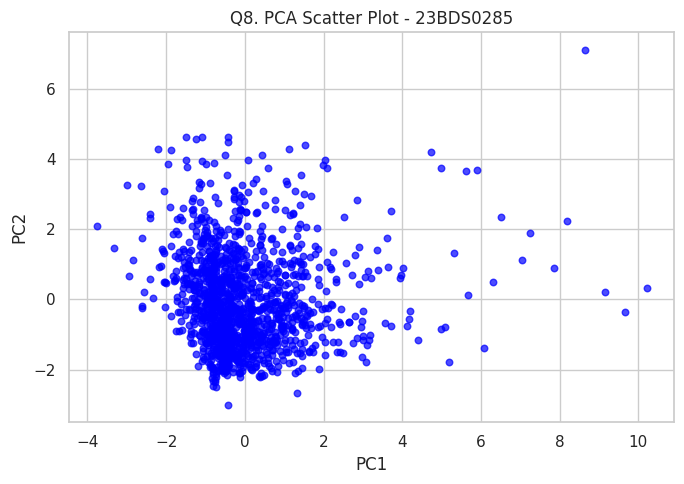

In [147]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(pca_scores_a9["PC1"], pca_scores_a9["PC2"], color="blue", marker="o", s=22, alpha=0.7)
ax.set(title="Q8. PCA Scatter Plot - 23BDS0285", xlabel="PC1", ylabel="PC2")
finish_plot("assessment09_q8_pc1_pc2.png", fig)

# Assessment 10: PCA Using Six mtcars Variables

**Q1. Select the numerical variables mpg, disp, hp, drat, wt, qsec from the mtcars dataset and examine their basic statistical characteristics.**

In [148]:
car_names = ["Mazda RX4", "Mazda RX4 Wag", "Datsun 710", "Hornet 4 Drive", "Hornet Sportabout", "Valiant",
             "Duster 360", "Merc 240D", "Merc 230", "Merc 280", "Merc 280C", "Merc 450SE", "Merc 450SL",
             "Merc 450SLC", "Cadillac Fleetwood", "Lincoln Continental", "Chrysler Imperial", "Fiat 128",
             "Honda Civic", "Toyota Corolla", "Toyota Corona", "Dodge Challenger", "AMC Javelin", "Camaro Z28",
             "Pontiac Firebird", "Fiat X1-9", "Porsche 914-2", "Lotus Europa", "Ford Pantera L", "Ferrari Dino",
             "Maserati Bora", "Volvo 142E"]
mtcars = pd.DataFrame({
    "mpg": [21.0,21.0,22.8,21.4,18.7,18.1,14.3,24.4,22.8,19.2,17.8,16.4,17.3,15.2,10.4,10.4,14.7,32.4,30.4,33.9,21.5,15.5,15.2,13.3,19.2,27.3,26.0,30.4,15.8,19.7,15.0,21.4],
    "disp": [160.0,160.0,108.0,258.0,360.0,225.0,360.0,146.7,140.8,167.6,167.6,275.8,275.8,275.8,472.0,460.0,440.0,78.7,75.7,71.1,120.1,318.0,304.0,350.0,400.0,79.0,120.3,95.1,351.0,145.0,301.0,121.0],
    "hp": [110,110,93,110,175,105,245,62,95,123,123,180,180,180,205,215,230,66,52,65,97,150,150,245,175,66,91,113,264,175,335,109],
    "drat": [3.90,3.90,3.85,3.08,3.15,2.76,3.21,3.69,3.92,3.92,3.92,3.07,3.07,3.07,2.93,3.00,3.23,4.08,4.93,4.22,3.70,2.76,3.15,3.73,3.08,4.08,4.43,3.77,4.22,3.62,3.54,4.11],
    "wt": [2.620,2.875,2.320,3.215,3.440,3.460,3.570,3.190,3.150,3.440,3.440,4.070,3.730,3.780,5.250,5.424,5.345,2.200,1.615,1.835,2.465,3.520,3.435,3.840,3.845,1.935,2.140,1.513,3.170,2.770,3.570,2.780],
    "qsec": [16.46,17.02,18.61,19.44,17.02,20.22,15.84,20.00,22.90,18.30,18.90,17.40,17.60,18.00,17.98,17.82,17.42,19.47,18.52,19.90,20.01,16.87,17.30,15.41,17.05,18.90,16.70,16.90,14.50,15.50,14.60,18.60],
}, index=car_names)


print(mtcars.head())
print(mtcars.describe().T)

                    mpg   disp   hp  drat     wt   qsec
Mazda RX4          21.0  160.0  110  3.90  2.620  16.46
Mazda RX4 Wag      21.0  160.0  110  3.90  2.875  17.02
Datsun 710         22.8  108.0   93  3.85  2.320  18.61
Hornet 4 Drive     21.4  258.0  110  3.08  3.215  19.44
Hornet Sportabout  18.7  360.0  175  3.15  3.440  17.02
      count        mean         std     min        25%      50%     75%      max
mpg    32.0   20.090625    6.026948  10.400   15.42500   19.200   22.80   33.900
disp   32.0  230.721875  123.938694  71.100  120.82500  196.300  326.00  472.000
hp     32.0  146.687500   68.562868  52.000   96.50000  123.000  180.00  335.000
drat   32.0    3.596563    0.534679   2.760    3.08000    3.695    3.92    4.930
wt     32.0    3.217250    0.978457   1.513    2.58125    3.325    3.61    5.424
qsec   32.0   17.848750    1.786943  14.500   16.89250   17.710   18.90   22.900


**Q2. Standardize the selected variables before applying PCA. Explain why standardization is required.**

In [149]:
mtcars_scaler = StandardScaler()
mtcars_scaled = pd.DataFrame(mtcars_scaler.fit_transform(mtcars), columns=mtcars.columns, index=mtcars.index)
print(mtcars_scaled.head())
print("Standardization puts variables on comparable scales so variables measured in large units do not dominate PCA.")

                        mpg      disp        hp      drat        wt      qsec
Mazda RX4          0.153299 -0.579750 -0.543655  0.576594 -0.620167 -0.789601
Mazda RX4 Wag      0.153299 -0.579750 -0.543655  0.576594 -0.355382 -0.471202
Datsun 710         0.456737 -1.006026 -0.795570  0.481584 -0.931678  0.432823
Hornet 4 Drive     0.220730  0.223615 -0.543655 -0.981576 -0.002336  0.904736
Hornet Sportabout -0.234427  1.059772  0.419550 -0.848562  0.231297 -0.471202
Standardization puts variables on comparable scales so variables measured in large units do not dominate PCA.


**Q3. Perform PCA using the prcomp() function in R.**

In [150]:
mtcars_pca = PCA()
mtcars_scores_array = mtcars_pca.fit_transform(mtcars_scaled)
mtcars_scores = pd.DataFrame(mtcars_scores_array, index=mtcars.index,
                             columns=[f"PC{i}" for i in range(1, len(mtcars.columns) + 1)])
mtcars_loadings = pd.DataFrame(mtcars_pca.components_.T, index=mtcars.columns,
                               columns=mtcars_scores.columns)
print("PCA loadings:\n", mtcars_loadings.round(4))
print("Explained variance ratio:\n", mtcars_pca.explained_variance_ratio_)

PCA loadings:
          PC1     PC2     PC3     PC4     PC5     PC6
mpg  -0.4587 -0.0587 -0.1948  0.7821  0.1112  0.3525
disp  0.4660  0.0607  0.0969  0.6000 -0.2946 -0.5683
hp    0.4259 -0.3615  0.1461  0.1230  0.8057  0.0477
drat -0.3671 -0.4365  0.8005  0.0226 -0.1438 -0.1128
wt    0.4386  0.2995  0.4178  0.1044 -0.2302  0.6925
qsec -0.2528  0.7628  0.3406  0.0427  0.4219 -0.2415
Explained variance ratio:
 [0.69789941 0.19135202 0.05555944 0.02572676 0.02079933 0.00866303]


**Q4. Determine the proportion of variance explained by each principal component.**

In [151]:
mtcars_variance_ratio = mtcars_pca.explained_variance_ratio_
mtcars_variance_table = pd.DataFrame({
    "Component": mtcars_scores.columns,
    "Proportion": mtcars_variance_ratio,
    "Percentage": mtcars_variance_ratio * 100,
    "Cumulative (%)": np.cumsum(mtcars_variance_ratio) * 100,
})
print(mtcars_variance_table.round(4))

  Component  Proportion  Percentage  Cumulative (%)
0       PC1      0.6979     69.7899         69.7899
1       PC2      0.1914     19.1352         88.9251
2       PC3      0.0556      5.5559         94.4811
3       PC4      0.0257      2.5727         97.0538
4       PC5      0.0208      2.0799         99.1337
5       PC6      0.0087      0.8663        100.0000


**Q5. Identify the minimum number of principal components required to explain at least 80% of the total variance.**

In [152]:
minimum_components_80 = int(np.searchsorted(np.cumsum(mtcars_variance_ratio), 0.80) + 1)
print("Minimum Principal Components Required:", minimum_components_80)
print(f"Cumulative variance explained: {np.cumsum(mtcars_variance_ratio)[minimum_components_80 - 1] * 100:.2f}%")

Minimum Principal Components Required: 2
Cumulative variance explained: 88.93%


**Q6. Construct a scree plot and interpret the importance of the principal components.**

Plot saved: /content/eda_project_outputs/assessment10_q6_scree_plot.png


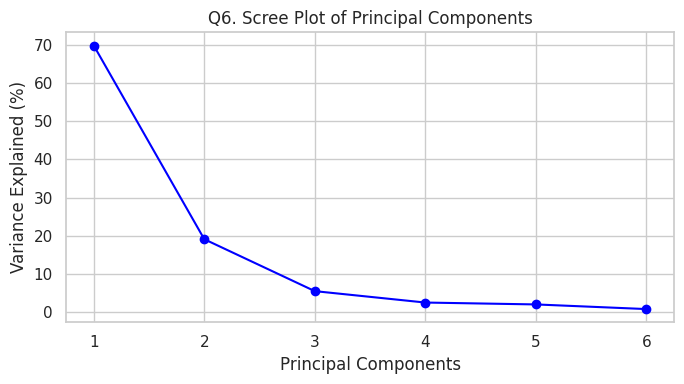

Variance explained (%): [69.79, 19.14, 5.56, 2.57, 2.08, 0.87]
The first component explains the largest share; later components usually add progressively less variance.


In [153]:
fig, ax = plt.subplots(figsize=(7, 4))
component_positions = np.arange(1, len(mtcars_variance_ratio) + 1)
ax.plot(component_positions, mtcars_variance_ratio * 100, marker="o", color="blue")
ax.set(title="Q6. Scree Plot of Principal Components", xlabel="Principal Components", ylabel="Variance Explained (%)")
ax.set_xticks(component_positions)
finish_plot("assessment10_q6_scree_plot.png", fig)
print("Variance explained (%):", np.round(mtcars_variance_ratio * 100, 2).tolist())
print("The first component explains the largest share; later components usually add progressively less variance.")

**Q7. Examine the PCA loadings and identify which original variables contribute most strongly to PC1 and PC2.**

In [154]:
for component in ["PC1", "PC2"]:
    strong_variables = mtcars_loadings[component].abs().sort_values(ascending=False)
    print(f"Strongest absolute loadings for {component}:\n", strong_variables.head(3))

Strongest absolute loadings for PC1:
 disp    0.466035
mpg     0.458684
wt      0.438618
Name: PC1, dtype: float64
Strongest absolute loadings for PC2:
 qsec    0.762849
drat    0.436525
hp      0.361476
Name: PC2, dtype: float64


**Q8. Create a PCA biplot and interpret the relationships among the automobiles and the original variables.**

Plot saved: /content/eda_project_outputs/assessment10_q8_pca_biplot.png


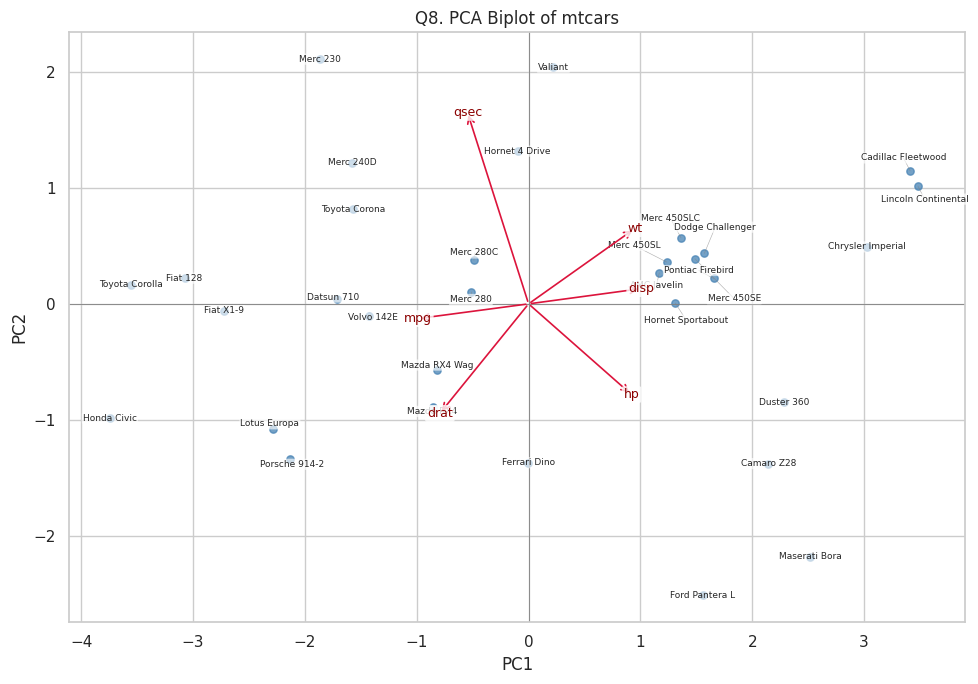

Cars near each other have similar profiles across the selected standardized variables.
Variables with arrows pointing in similar directions tend to be positively associated in the PCA plane.

ALL ASSIGNMENT SECTIONS COMPLETED.
Review generated plots in: /content/eda_project_outputs


In [155]:
mtcars_loadings_xy = mtcars_pca.components_.T[:, :2]
mtcars_scores_xy = mtcars_scores_array[:, :2]
mtcars_score_limit = max(np.percentile(np.abs(mtcars_scores_xy), 90), 1.0)
mtcars_loading_limit = max(np.max(np.abs(mtcars_loadings_xy)), 1e-9)
mtcars_arrow_scale = 0.62 * mtcars_score_limit / mtcars_loading_limit
mtcars_arrow_ends = mtcars_loadings_xy * mtcars_arrow_scale
mtcars_spread = max(np.ptp(mtcars_scores_xy[:, 0]), np.ptp(mtcars_scores_xy[:, 1]))
mtcars_repel = repel_positions(mtcars_scores_xy, minimum_distance=0.055 * mtcars_spread, iterations=220)
mtcars_repel_loadings = repel_positions(mtcars_arrow_ends, minimum_distance=0.07 * mtcars_spread, iterations=220)
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(mtcars_scores_xy[:, 0], mtcars_scores_xy[:, 1], color="steelblue", s=28, alpha=0.75, label="Automobiles")
for i, car in enumerate(mtcars.index):
    ax.plot([mtcars_scores_xy[i, 0], mtcars_repel[i, 0]], [mtcars_scores_xy[i, 1], mtcars_repel[i, 1]], color="gray", linewidth=0.45, alpha=0.6)
    ax.text(mtcars_repel[i, 0], mtcars_repel[i, 1], car, fontsize=6.5, ha="center", va="center",
            bbox={"boxstyle": "round,pad=0.12", "fc": "white", "ec": "none", "alpha": 0.65})
for i, variable in enumerate(mtcars.columns):
    xe, ye = mtcars_arrow_ends[i]
    xl, yl = mtcars_repel_loadings[i]
    ax.annotate("", xy=(xe, ye), xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": "crimson", "lw": 1.2})
    ax.plot([xe, xl], [ye, yl], color="crimson", linewidth=0.6, alpha=0.65)
    ax.text(xl, yl, variable, color="darkred", fontsize=9, ha="center", va="center",
            bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.8})
ax.axhline(0, color="gray", linewidth=0.6)
ax.axvline(0, color="gray", linewidth=0.6)
ax.set(title="Q8. PCA Biplot of mtcars", xlabel="PC1", ylabel="PC2")
finish_plot("assessment10_q8_pca_biplot.png", fig)
print("Cars near each other have similar profiles across the selected standardized variables.")
print("Variables with arrows pointing in similar directions tend to be positively associated in the PCA plane.")

print("\nALL ASSIGNMENT SECTIONS COMPLETED.")
print(f"Review generated plots in: {OUTPUT_DIR}")